# Evaluación Parcial 2 — Clasificación de enfermedades en hojas con CNN (PlantVillage)

**Asignatura:** Deep Learning (DLY0100) · **Integrantes:** Benjamín Arratia y Ángel

**Objetivo:** clasificar fotografías de hojas de pimiento, papa y tomate en **15 clases** (sanas y con distintas enfermedades) usando redes neuronales convolucionales en TensorFlow/Keras, ajustar sus hiperparámetros y justificar con evidencia el modelo final. Usamos el dataset público PlantVillage, con el que trabajos previos mostraron que una CNN puede diagnosticar enfermedades a partir de fotos de hojas.

| Sección | Contenido |
| :--- | :--- |
| 1–2 | Carga, separación entrenamiento/validación/prueba y preprocesamiento |
| 3 | Arquitectura CNN base y justificación |
| 4–7 | Entrenamiento y evaluación del modelo base |
| 8 | Optimización y ajuste de hiperparámetros (búsqueda en grilla y verificación con varias semillas) |
| 9 | Justificación del modelo final (comparación con alternativas y evaluación en prueba) |


### Descompresión del conjunto de datos

Usaremos el comando `unzip` para extraer las imágenes y carpetas de `PlantVillage.zip` de forma silenciosa (usando `-q` para no saturar la salida).

In [ ]:
import zipfile
import os
import shutil

zip_path = '/content/PlantVillage.zip'
extract_path = '/content/PlantVillage'

if os.path.exists(zip_path):
    # Limpiar cualquier residuo de una extracción fallida anterior para evitar conflictos
    if os.path.exists(extract_path):
        shutil.rmtree(extract_path)
    try:
        print("Iniciando la descompresión del archivo completo de 684 MB...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
        print("¡Descompresión completada con éxito!")
    except Exception as e:
        print(f"Error al descomprimir: {e}")
else:
    print("No se encontró /content/PlantVillage.zip: se buscará la carpeta del dataset ya extraída.")

No se encontró /content/PlantVillage.zip: se buscará la carpeta del dataset ya extraída.


## 1. Importación de Librerías y Carga de Datos

Importamos las librerías necesarias y cargamos las imágenes de PlantVillage.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import json
import time
import random
import filecmp
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, recall_score, f1_score, accuracy_score

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

EXTENSIONES = ('.jpg', '.jpeg', '.png')
CARPETA_DUPLICADA = 'PlantVillage'


def buscar_raiz_dataset():
    # Devuelve la primera carpeta que contiene directamente las carpetas de clases
    candidatos = [os.environ.get('PLANTVILLAGE_DIR', ''), '/content/PlantVillage', 'PlantVillage.rar', 'PlantVillage', '.']
    for base in candidatos:
        if base and os.path.isdir(base):
            for dirpath, dirnames, _ in os.walk(base):
                if 'Tomato_healthy' in dirnames:
                    return dirpath
    raise FileNotFoundError('No se encontró la carpeta del dataset PlantVillage')


dataset_dir = buscar_raiz_dataset()
subcarpetas = sorted(d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d)))
class_names = [d for d in subcarpetas if d != CARPETA_DUPLICADA]
num_classes = len(class_names)
print(f"Carpeta del dataset: {dataset_dir}")
print(f"Subcarpetas encontradas: {len(subcarpetas)} -> clases reales: {num_classes}")

# Evidencia de la duplicación: misma estructura y mismos archivos dentro de 'PlantVillage/'
ruta_dup = os.path.join(dataset_dir, CARPETA_DUPLICADA)
if os.path.isdir(ruta_dup):
    pares = []
    for c in class_names:
        for f in os.listdir(os.path.join(ruta_dup, c)) if os.path.isdir(os.path.join(ruta_dup, c)) else []:
            original = os.path.join(dataset_dir, c, f)
            if os.path.exists(original):
                pares.append((original, os.path.join(ruta_dup, c, f)))
    muestra = random.Random(SEED).sample(pares, min(300, len(pares)))
    identicos = sum(filecmp.cmp(a, b, shallow=False) for a, b in muestra)
    print(f"La subcarpeta '{CARPETA_DUPLICADA}/' repite {len(pares)} archivos con el mismo nombre y clase; "
          f"en una muestra de {len(muestra)}, {identicos} son idénticos byte a byte -> se excluye.")

# Lista de rutas y etiquetas (solo archivos de imagen)
rutas, etiquetas = [], []
for indice, clase in enumerate(class_names):
    archivos = sorted(f for f in glob.glob(os.path.join(dataset_dir, clase, '*')) if f.lower().endswith(EXTENSIONES))
    rutas += archivos
    etiquetas += [indice] * len(archivos)
rutas, etiquetas = np.array(rutas), np.array(etiquetas)

# Separación estratificada 70 / 15 / 15
rutas_tmp, rutas_test, y_tmp, y_test = train_test_split(rutas, etiquetas, test_size=0.15, stratify=etiquetas, random_state=SEED)
rutas_train, rutas_val, y_train, y_val = train_test_split(rutas_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)

distribucion = pd.DataFrame({
    'entrenamiento': np.bincount(y_train, minlength=num_classes),
    'validación': np.bincount(y_val, minlength=num_classes),
    'prueba': np.bincount(y_test, minlength=num_classes)}, index=class_names)
distribucion['total'] = distribucion.sum(axis=1)
print(f"\nImágenes únicas: {len(rutas)} | entrenamiento {len(y_train)} | validación {len(y_val)} | prueba {len(y_test)}")
display(distribucion)
print(f"Desbalance: la clase mayor tiene {distribucion.total.max() / distribucion.total.min():.1f} veces más imágenes que la menor.")

# Configuración de hiperparámetros de carga
BATCH_SIZE = 32
IMG_SIZE = (150, 150) if tf.config.list_physical_devices('GPU') else (64, 64)  # En CPU reducimos el modelo base


def cargar_imagenes(lista_rutas, size):
    # Decodifica y redimensiona en paralelo; devuelve un arreglo uint8 (N, alto, ancho, 3)
    def leer(ruta):
        with Image.open(ruta) as im:
            return np.asarray(im.convert('RGB').resize(size, Image.BILINEAR), dtype=np.uint8)
    with ThreadPoolExecutor(max_workers=8) as ex:
        return np.stack(list(ex.map(leer, lista_rutas)))


t0 = time.time()
X_train, X_val, X_test = (cargar_imagenes(r, IMG_SIZE) for r in (rutas_train, rutas_val, rutas_test))
print(f"Imágenes cargadas en {time.time() - t0:.0f} s: {X_train.shape}, {X_val.shape}, {X_test.shape}")

# Datasets de TensorFlow usados por el modelo base (secciones 3 a 7)
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(BATCH_SIZE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE)

print(f"\nClases detectadas ({num_classes}): {class_names}")

Carpeta del dataset: /Users/benja/Dev/ev2-data/PlantVillage
Subcarpetas encontradas: 16 -> clases reales: 15


La subcarpeta 'PlantVillage/' repite 20639 archivos con el mismo nombre y clase; en una muestra de 300, 300 son idénticos byte a byte -> se excluye.

Imágenes únicas: 20638 | entrenamiento 14446 | validación 3096 | prueba 3096


,entrenamiento,validación,prueba,total
Pepper__bell___Bacterial_spot,698,150,149,997
Pepper__bell___healthy,1034,222,222,1478
Potato___Early_blight,700,150,150,1000
Potato___Late_blight,700,150,150,1000
Potato___healthy,106,23,23,152
Tomato_Bacterial_spot,1489,319,319,2127
Tomato_Early_blight,700,150,150,1000
Tomato_Late_blight,1337,286,286,1909
Tomato_Leaf_Mold,666,143,143,952
Tomato_Septoria_leaf_spot,1239,266,266,1771


Desbalance: la clase mayor tiene 21.1 veces más imágenes que la menor.


Imágenes cargadas en 3 s: (14446, 64, 64, 3), (3096, 64, 64, 3), (3096, 64, 64, 3)

Clases detectadas (15): ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


### 1.1 Exploración visual de los datos

**Cómo.** Graficamos cuántas imágenes tiene cada clase en entrenamiento, validación y prueba, y mostramos una hoja de ejemplo por clase.

**Por qué.** Antes de elegir arquitectura y métrica hay que saber dos cosas: si las clases están balanceadas (define si alcanza con accuracy) y cómo son las imágenes (define la resolución y qué tan difícil es distinguir enfermedades parecidas).

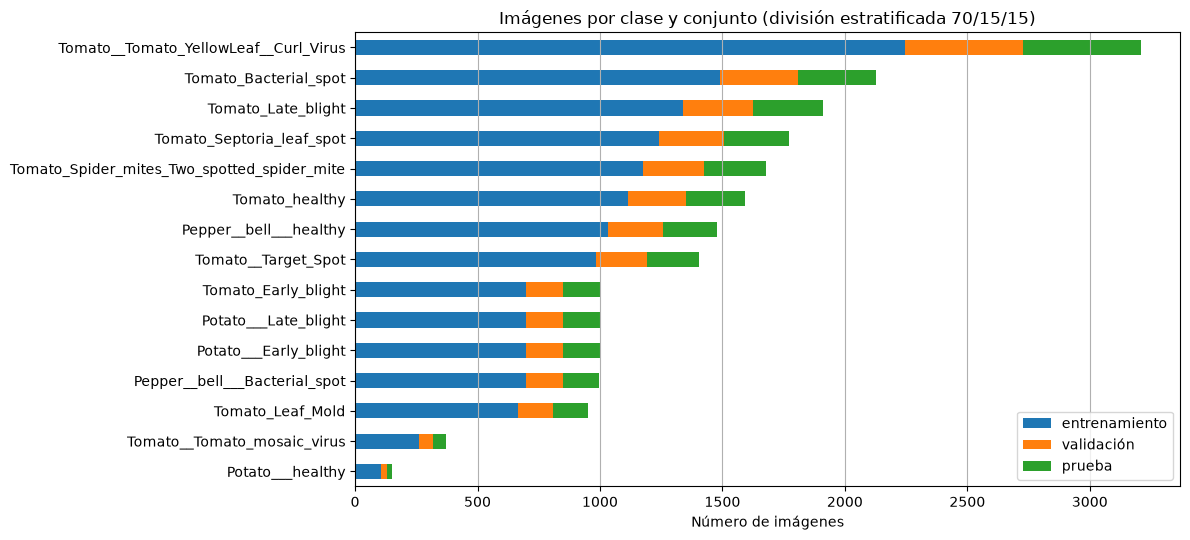

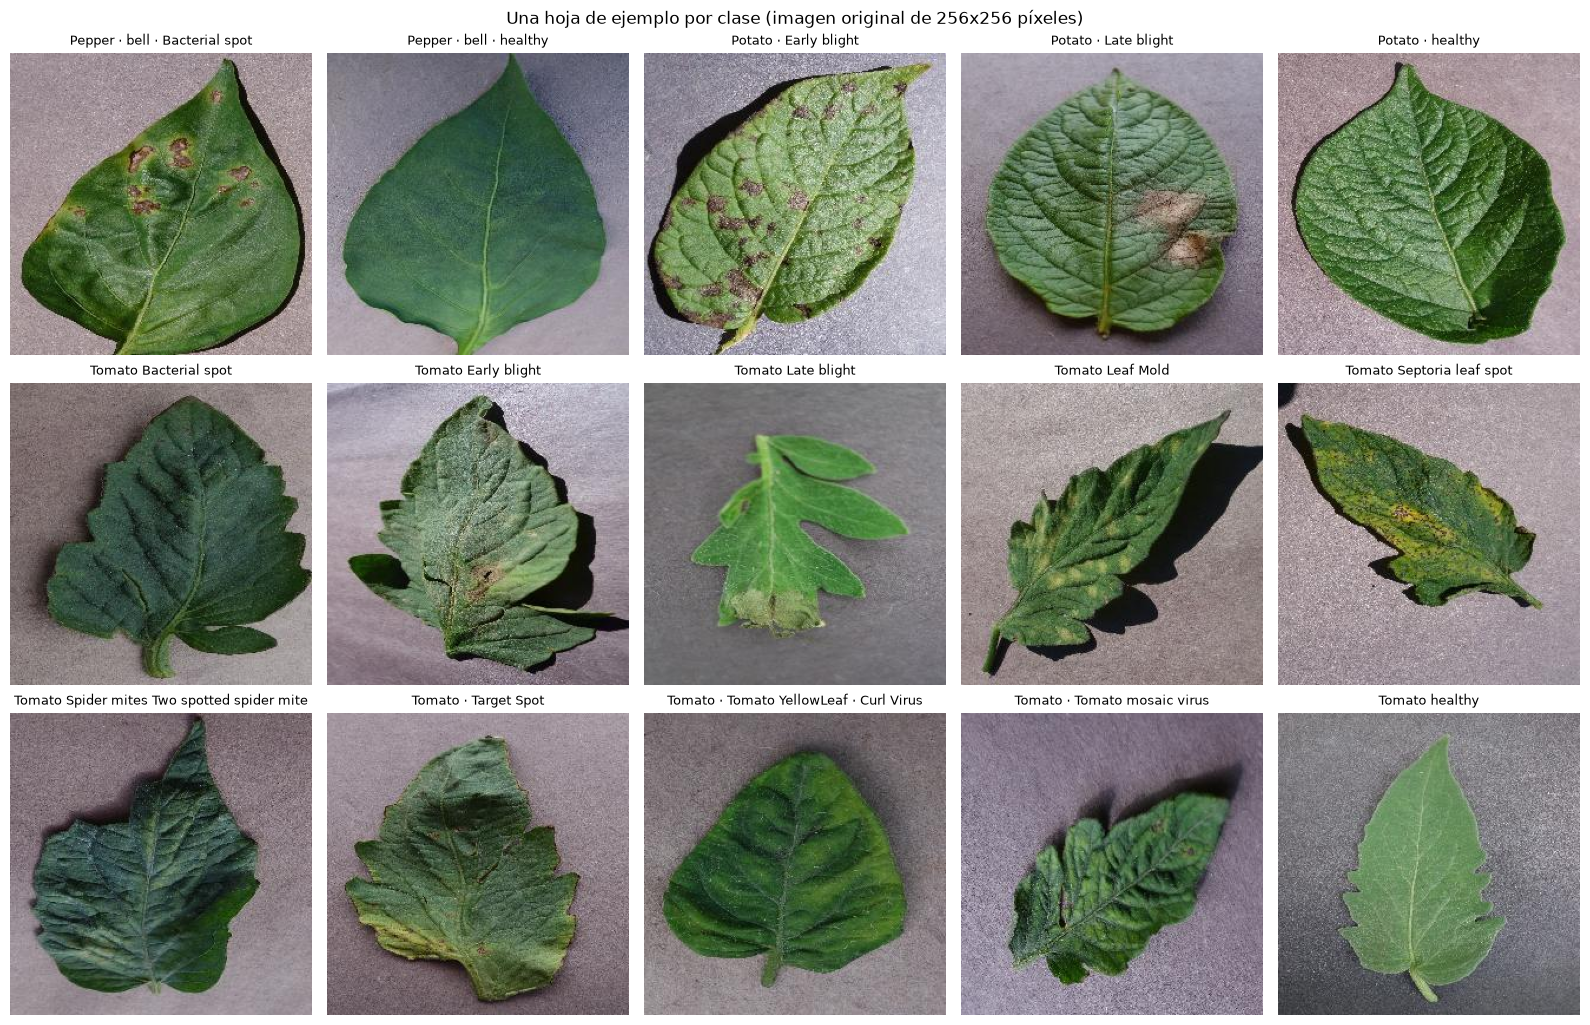

**Qué pasó.** La clase más grande es **Tomato__Tomato_YellowLeaf__Curl_Virus** (3208 imágenes) y la más chica **Potato___healthy** (152): **21.1 veces** de diferencia. Hay 3 clases sanas y 12 enfermas, así que el modelo ve muchos más ejemplos de enfermedad que de hoja sana. **Consecuencias para el resto del trabajo:** (1) el accuracy puede verse alto aunque el modelo falle en las clases chicas, por eso seleccionamos con **F1 macro**, que pesa igual a las 15 clases; (2) la división es **estratificada**, para que validación y prueba tengan las mismas proporciones; (3) en prueba, Potato___healthy tiene solo 23 imágenes, así que su F1 será la métrica menos estable. Las fotos son de una sola hoja, centrada y con fondo uniforme, tomadas en condiciones controladas: eso facilita la tarea, pero limita cómo se generaliza a fotos de campo (sección 9.4). Varias enfermedades del tomate se ven parecidas a simple vista (manchas oscuras en la hoja), lo que anticipa confusiones entre ellas.

In [ ]:
from IPython.display import Markdown, display

# 1) Desbalance: imágenes por clase en cada conjunto (sin la carpeta duplicada)
orden = distribucion.sort_values('total').index
fig, eje = plt.subplots(figsize=(12, 5.5))
distribucion.loc[orden, ['entrenamiento', 'validación', 'prueba']].plot.barh(stacked=True, ax=eje)
eje.set_title('Imágenes por clase y conjunto (división estratificada 70/15/15)')
eje.set_xlabel('Número de imágenes')
eje.grid(True, axis='x')
plt.tight_layout()
plt.show()

# 2) Una hoja de ejemplo por clase (primera imagen de entrenamiento de cada clase, tamaño original)
fig, ejes = plt.subplots(3, 5, figsize=(16, 10.5))
for eje, (indice, clase) in zip(ejes.flat, enumerate(class_names)):
    ruta = rutas_train[np.where(y_train == indice)[0][0]]
    with Image.open(ruta) as im:
        eje.imshow(im.convert('RGB'))
        tam = im.size
    eje.set_title(clase.replace('___', ' · ').replace('__', ' · ').replace('_', ' '), fontsize=9)
    eje.axis('off')
plt.suptitle(f'Una hoja de ejemplo por clase (imagen original de {tam[0]}x{tam[1]} píxeles)')
plt.tight_layout()
plt.show()

mayor, menor = distribucion.total.idxmax(), distribucion.total.idxmin()
sanas = [c for c in class_names if 'healthy' in c]
display(Markdown(f"""**Qué pasó.** La clase más grande es **{mayor}** ({distribucion.total.max()} imágenes) y la más chica **{menor}** ({distribucion.total.min()}): **{distribucion.total.max() / distribucion.total.min():.1f} veces** de diferencia. Hay {len(sanas)} clases sanas y {num_classes - len(sanas)} enfermas, así que el modelo ve muchos más ejemplos de enfermedad que de hoja sana. **Consecuencias para el resto del trabajo:** (1) el accuracy puede verse alto aunque el modelo falle en las clases chicas, por eso seleccionamos con **F1 macro**, que pesa igual a las 15 clases; (2) la división es **estratificada**, para que validación y prueba tengan las mismas proporciones; (3) en prueba, {menor} tiene solo {distribucion.loc[menor, 'prueba']} imágenes, así que su F1 será la métrica menos estable. Las fotos son de una sola hoja, centrada y con fondo uniforme, tomadas en condiciones controladas: eso facilita la tarea, pero limita cómo se generaliza a fotos de campo (sección 9.4). Varias enfermedades del tomate se ven parecidas a simple vista (manchas oscuras en la hoja), lo que anticipa confusiones entre ellas."""))


## 2. Preprocesamiento de Datos

Decodificamos cada imagen una sola vez como `uint8` y guardamos esos arreglos en memoria para reutilizarlos. Las etiquetas son enteros (`sparse_categorical_crossentropy`); no hace falta One-Hot. No usamos caché adicional porque duplicaría los arreglos en RAM.

Como las imágenes ya se cargaron en memoria como `uint8`, la normalización a $[0, 1]$ se hace dentro del modelo con la capa `Rescaling`, de modo que el mismo preprocesamiento viaja con el modelo al momento de predecir.


In [ ]:
# Capa de normalización incorporada en el pipeline o en el modelo [0, 1]
normalization_layer = layers.Rescaling(1./255)

# Optimizar el rendimiento de la lectura de disco
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Datasets optimizados y listos para el entrenamiento.")

Datasets optimizados y listos para el entrenamiento.


## 3. Construcción del Modelo CNN

Diseñaremos la red neuronal convolucional siguiendo la estructura de la plantilla: 2 capas convolucionales (`Conv2D`), cada una con su respectiva reducción espacial (`MaxPooling2D`), seguidas de un aplanado (`Flatten`), una capa densa intermedia (`Dense` con activación ReLU y regularización opcional mediante Dropout) y finalmente la capa de salida adaptada a las 15 clases de PlantVillage.

In [ ]:
# Definición del modelo secuencial basándose en la plantilla original
model = keras.Sequential([
    # Capa de entrada y reescalado de píxeles
    layers.Input(shape=(*IMG_SIZE, 3)),
    normalization_layer,

    # Primera Capa Convolucional
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Segunda Capa Convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Aplanado de los mapas de características
    layers.Flatten(),

    # Capa Totalmente Conectada (Densa)
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Capa de salida con activación Softmax para clasificación multiclase
    layers.Dense(num_classes, activation='softmax')
])

# Compilación del modelo utilizando la pérdida categórica escasa
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Mostrar la arquitectura del modelo
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,627,087 (6.21 MB)

 Trainable params: 1,627,087 (6.21 MB)

 Non-trainable params: 0 (0.00 B)

### Justificación de la Arquitectura y Selección de Herramientas

#### 1. ¿Por qué una Red Neuronal Convolucional (CNN)?
Para el análisis de imágenes, las redes totalmente conectadas (MLP) sufren de la "maldición de la dimensionalidad" y pierden la información espacial local. Las CNNs introducen dos conceptos clave:
* **Compartición de pesos (Weight Sharing):** Reduce drásticamente el número de parámetros.
* **Invarianza a la traslación:** Permite detectar características (bordes, texturas de hojas, manchas de enfermedades) sin importar su posición exacta en la imagen.

#### 2. Justificación de los Componentes del Modelo Seleccionado
* **Capas Convolucionales (`Conv2D`):** Usamos filtros de $3 \times 3$, estándar en visión por computadora, que capturan patrones espaciales de grano fino en las primeras capas.
* **Capas de Reducción (`MaxPooling2D`):** Reducen a la mitad las dimensiones espaciales, lo que disminuye el costo computacional y ayuda a construir una representación invariante a pequeñas variaciones.
* **Capa Densa (`Dense(128)`) + Dropout:** La capa densa combina las características extraídas para la clasificación. Introducir `Dropout(0.5)` durante el entrenamiento apaga aleatoriamente el 50% de las neuronas, forzando a la red a no co-depender de neuronas específicas, reduciendo drásticamente el sobreajuste (*overfitting*).

#### 3. Comparación de Alternativas
* **CNN básica (punto de partida):** Permite medir el resultado inicial; tiene 10,6 millones de parámetros a 150×150 y puede ser lenta en CPU. Su rendimiento se mide en las secciones 4–7.
* **MobileNetV2 preentrenada:** Puede aprovechar características de ImageNet; no se presupone que sea mejor o más pesada: se compara experimentalmente con la CNN compacta en la sección 9.

### 3.1 Detalle de la Configuración de Capas e Hiperparámetros

La arquitectura secuencial propuesta está diseñada específicamente para equilibrar la capacidad de extracción de características complejas (como patrones de textura y color en las hojas) con la eficiencia computacional:

| Capa / Operación | Configuración / Filtros | Tamaño de Salida | Propósito y Justificación |
| :--- | :--- | :--- | :--- |
| **Entrada (Input)** | RGB Image | $(150, 150, 3)$ | Resolución estándar balanceada. Evita cuellos de botella de memoria en comparación con $224 \times 224$. |
| **Reescalado (Rescaling)** | $\times 1./255$ | $(150, 150, 3)$ | Normaliza los valores de píxeles $[0, 255]$ al rango $[0, 1]$, permitiendo una convergencia más estable y rápida del optimizador. |
| **Convolución 1 (Conv2D)** | 32 filtros, $3 \times 3$, ReLU | $(148, 148, 32)$ | Extrae características espaciales de bajo nivel como bordes y gradientes de color simples de las hojas. |
| **Max Pooling 1** | Pool $2 \times 2$ | $(74, 74, 32)$ | Reduce a la mitad las dimensiones espaciales, conservando las características más destacadas de las texturas. |
| **Convolución 2 (Conv2D)** | 64 filtros, $3 \times 3$, ReLU | $(72, 72, 64)$ | Combina características simples para detectar patrones de nivel medio como formas de manchas de hongos o lesiones foliares. |
| **Max Pooling 2** | Pool $2 \times 2$ | $(36, 36, 64)$ | Nueva reducción espacial para mantener la invarianza a escala y limitar los parámetros de la capa densa subsiguiente. |
| **Aplanado (Flatten)** | Vectorización | $(82944,)$ | Transforma el tensor tridimensional resultante en un vector unidimensional apto para la clasificación final. |
| **Densa (Fully Connected)** | 128 neuronas, ReLU | $(128,)$ | Espacio latente donde se asocian de forma no lineal las características espaciales con las clases correspondientes. |
| **Abandono (Dropout)** | Tasa de $0.5$ ($50\%$) | $(128,)$ | Regularización clave que reduce la co-adaptación de neuronas; su efecto real sobre el sobreajuste se mide en 8.4. |
| **Salida (Dense)** | 15 neuronas, Softmax | $(15,)$ | Genera una distribución de probabilidad multiclase sobre las 15 categorías (enfermedades y hojas sanas) de PlantVillage. |

---

### 3.2 Análisis del Impacto de los Hiperparámetros en el Rendimiento

El ajuste de hiperparámetros determina críticamente la capacidad de generalización y la estabilidad del entrenamiento. A continuación, se detalla el análisis del impacto de cada configuración:

#### 1. Tamaño del Lote (`BATCH_SIZE = 32`)
* **Impacto:** Un tamaño de lote de 32 ofrece un excelente equilibrio entre la precisión de la estimación del gradiente y el uso de memoria RAM/GPU en Colab.
* **Efectos de Ajuste:**
  * *Lotes más pequeños (ej. 16):* Introducen más ruido estocástico durante el descenso de gradiente (actúa como regularizador natural), pero ralentizan el tiempo de entrenamiento por época al no aprovechar al máximo la paralelización de la GPU.
  * *Lotes más grandes (ej. 64 o 128):* Hacen que el entrenamiento sea más rápido y estable, pero reducen las actualizaciones por época y requieren más memoria por lote; se evalúa su interacción con el optimizador y el LR en la grilla A.

#### 2. Tasa de Aprendizaje (`Learning Rate = 1e-3` por defecto en Adam)
* **Impacto:** Controla el tamaño del paso dado hacia el mínimo de la función de pérdida.
* **Efectos de Ajuste:**
  * *Muy alta (ej. $> 1e-2$):* El modelo diverge rápidamente; las curvas de pérdida oscilan salvajemente o se disparan a `NaN`.
  * *Muy baja (ej. $< 1e-4$):* La red aprende de manera extremadamente lenta, corriendo el riesgo de estancarse en mínimos locales subóptimos durante las primeras épocas.

#### 3. Tasa de Regularización `Dropout = 0.5`
* **Impacto:** Actúa como un interruptor de regularización dinámico.
* **Efectos de Ajuste:**
  * *Sin Dropout (0.0):* La red podría sobreajustarse y mostrar una brecha entre entrenamiento y validación. No se presuponen cifras: se miden en la grilla B (sección 8.4).
  * *Dropout muy alto (ej. 0.7):* Puede limitar drásticamente la capacidad del modelo para aprender patrones complejos, provocando un subajuste (*underfitting*) generalizado.

**Nota sobre CPU:** los tamaños de las tablas anteriores describen la versión base con GPU a 150×150; sin GPU se usa 64×64 (sección 1), cambian las formas y los parámetros, que `model.summary()` muestra de forma efectiva.


### 3.3 Evidencia experimental del impacto de los hiperparámetros

La versión anterior de esta sección mostraba curvas **simuladas** (valores escritos a mano) para ilustrar el efecto de la tasa de aprendizaje y del Dropout. Se reemplazaron por **experimentos reales**: la sección 8 entrena y compara cada configuración con métricas medidas sobre validación, y la sección 9 justifica el modelo final con la evaluación en prueba.

### 3.4 Herramientas utilizadas: ventajas, limitaciones y aporte

| Herramienta | Para qué la usamos | Ventajas | Limitaciones | Aporte a la solución |
| :--- | :--- | :--- | :--- | :--- |
| **TensorFlow 2 / Keras** [11] | Definir, entrenar y evaluar todas las CNN | API de alto nivel (`Sequential`, `fit`, *callbacks* como `EarlyStopping`); exigida por la pauta; corre igual en CPU, GPU de Colab y Mac; incluye modelos preentrenados | Menos control fino que un ciclo de entrenamiento manual; la versión de TensorFlow cambia algunos resultados; en Mac solo usamos CPU | Permitió entrenar 18 + 12 + 9 + 3 modelos con el mismo código y medir todo con las mismas reglas |
| **Keras Applications (MobileNetV2)** [10] | Alternativa de *transfer learning* | Pesos preentrenados en ImageNet; liviana (2,3 M de parámetros) | Requiere ≥96×96 píxeles; congelada no se adapta a hojas | Sirvió como competidor fuerte para validar la elección final |
| **scikit-learn** [12] | División estratificada, métricas (F1, matriz de confusión) y Random Forest | Métricas estándar y probadas; línea base no neuronal en una línea | No trabaja con imágenes directamente: el Random Forest ve píxeles sueltos, sin estructura espacial | Mide el rendimiento con la misma vara para todos los modelos y comprueba que la CNN aporta |
| **PIL + NumPy** | Leer y redimensionar las imágenes una sola vez | Carga en memoria reutilizable por todos los experimentos (3 s a 64×64) | Todo el dataset vive en RAM (≈1,4 GB a 150×150) | Hizo viable repetir decenas de entrenamientos sin releer el disco |
| **pandas, Matplotlib y seaborn** | Tablas de resultados y gráficos | Resultados guardados en CSV y reanudables | — | Toda decisión queda respaldada por una tabla o un gráfico |
| **Google Colab / ejecución local** | Entorno de ejecución | Colab ofrece GPU gratis y el notebook corre en CPU sin cambios | La GPU de Colab no siempre está disponible (nos ocurrió); en CPU hubo que reducir resolución y épocas | El notebook se adapta solo al hardware disponible (sección 8.1) |

**¿Por qué no PyTorch?** Ofrece más control sobre el ciclo de entrenamiento y es muy usado en investigación, pero exige escribir ese ciclo a mano y la pauta pide TensorFlow. No lo comparamos experimentalmente: la comparación de herramientas de este trabajo es entre **familias de modelos** (CNN propia, red preentrenada y modelo clásico de scikit-learn), en la sección 9.2.

## 4. Entrenamiento del Modelo

Entrenamos la red convolucional utilizando el dataset optimizado. Guardaremos los resultados en la variable `history` para poder graficar el rendimiento en el siguiente paso.

In [ ]:
EPOCHS = 5 if tf.config.list_physical_devices('GPU') else 2

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/2
/Users/benja/Dev/ev2-venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
self.data_adapter = data_adapters.get_data_adapter(
452/452 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - accuracy: 0.4883 - loss: 1.6111 - val_accuracy: 0.7271 - val_loss: 0.8701
Epoch 2/2
452/452 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.6852 - loss: 0.9670 - val_accuracy: 0.7936 - val_loss: 0.6364


## 5. Curvas de Aprendizaje (Pérdida y Precisión)

Visualizaremos las curvas de precisión y pérdida para verificar si el modelo está convergiendo correctamente o si presenta problemas de sobreajuste (overfitting).

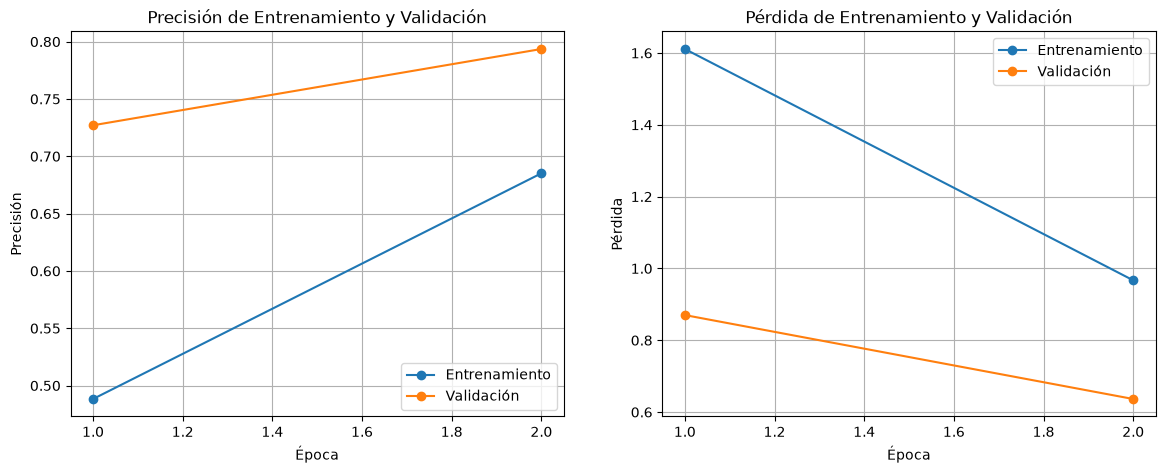

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epocas_range = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Gráfico de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epocas_range, acc, label='Entrenamiento', marker='o')
plt.plot(epocas_range, val_acc, label='Validación', marker='o')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend(loc='lower right')
plt.grid(True)

# Gráfico de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(epocas_range, loss, label='Entrenamiento', marker='o')
plt.plot(epocas_range, val_loss, label='Validación', marker='o')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend(loc='upper right')
plt.grid(True)

plt.show()

## 6. Matriz de Confusión en el Conjunto de Validación (Adaptado)

Evaluamos el rendimiento del modelo final sobre nuestro conjunto de validación, obteniendo las predicciones para graficar la matriz de confusión multiclase con `seaborn`.

Calculando predicciones en el conjunto de validación...


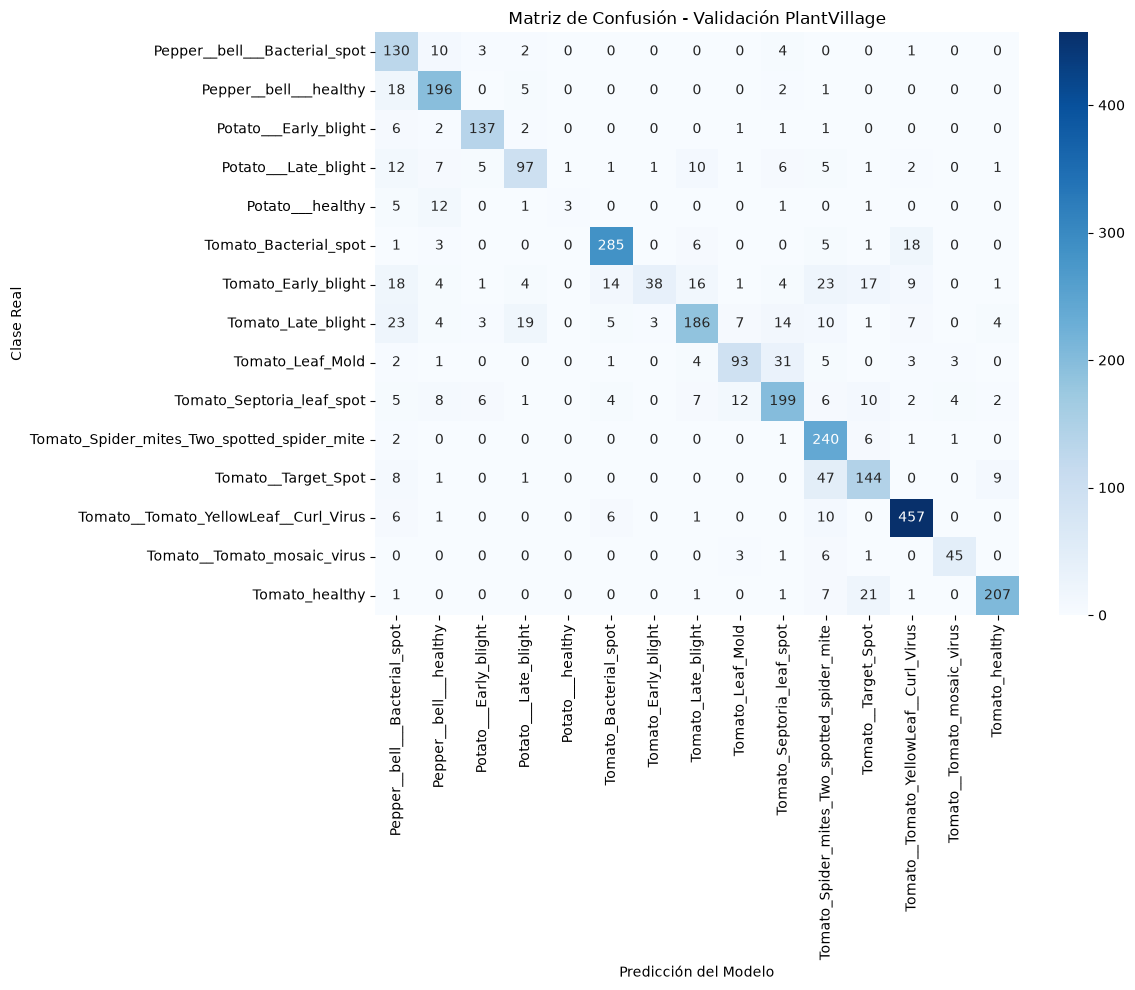

In [ ]:
# Extraer etiquetas reales y predicciones del dataset de validación
y_true = []
y_pred_classes = []

print("Calculando predicciones en el conjunto de validación...")
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred_classes.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred_classes = np.array(y_pred_classes)

# Crear y graficar la matriz de confusión
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión - Validación PlantVillage')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Clase Real')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 6.1 Reporte Detallado de Métricas de Desempeño

Para complementar la evaluación y cumplir formalmente con el análisis cuantitativo, calculamos las métricas clave: **Exactitud (Accuracy)**, **Precisión (Precision)**, **Sensibilidad (Recall)** y **F1-score** para cada una de las clases detectadas en el conjunto de validación.

In [ ]:
from sklearn.metrics import classification_report

# Generar el reporte de clasificación detallado por clase
reporte = classification_report(y_true, y_pred_classes, target_names=class_names)
print("=== REPORTE DE CLASIFICACIÓN DETALLADO ===\n")
print(reporte)

=== REPORTE DE CLASIFICACIÓN DETALLADO ===

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.55      0.87      0.67       150
                     Pepper__bell___healthy       0.79      0.88      0.83       222
                      Potato___Early_blight       0.88      0.91      0.90       150
                       Potato___Late_blight       0.73      0.65      0.69       150
                           Potato___healthy       0.75      0.13      0.22        23
                      Tomato_Bacterial_spot       0.90      0.89      0.90       319
                        Tomato_Early_blight       0.90      0.25      0.40       150
                         Tomato_Late_blight       0.81      0.65      0.72       286
                           Tomato_Leaf_Mold       0.79      0.65      0.71       143
                  Tomato_Septoria_leaf_spot       0.75      0.75      0.75       266
Tomato_Spider_mites_

## 7. Visualización de Imágenes Clasificadas Incorrectamente

Identificaremos de forma eficiente las muestras del conjunto de validación donde el modelo cometió un error y graficaremos un mosaico ilustrativo con las etiquetas reales frente a las predichas.

Total de clasificaciones incorrectas en validación: 639


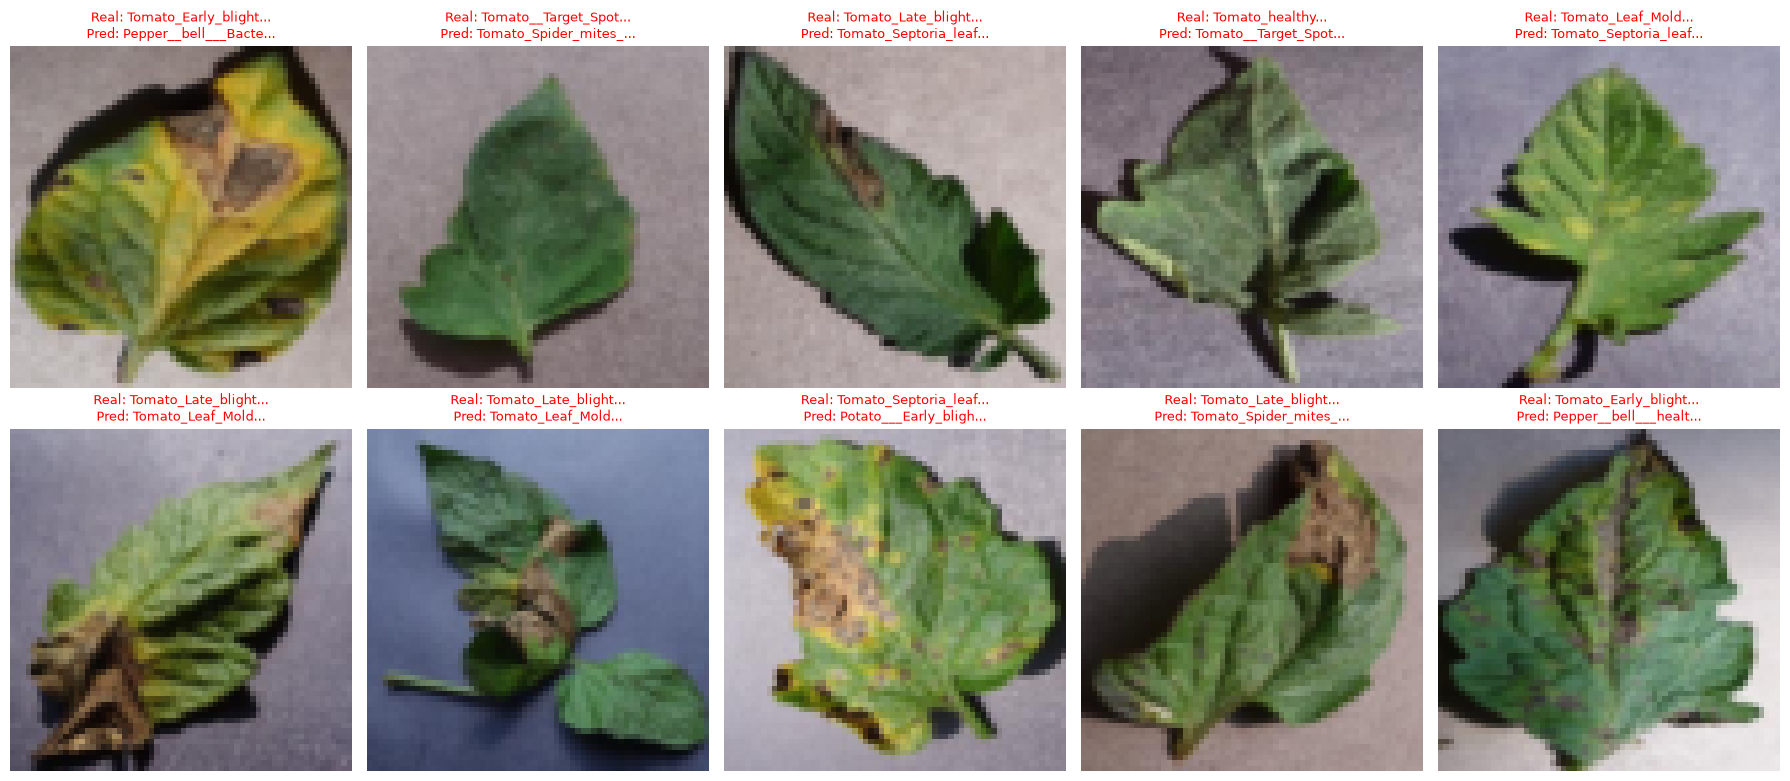

In [ ]:
# Encontrar índices de predicciones incorrectas
errores_indices = np.where(y_pred_classes != y_true)[0]
print(f"Total de clasificaciones incorrectas en validación: {len(errores_indices)}")

# Re-extraer algunas imágenes de validación para graficar las incorrectas
# Convertimos el dataset de validación a un iterador para recuperar un lote de imágenes de ejemplo
val_images_list = []
for images, labels in val_ds.unbatch().take(max(errores_indices) + 1 if len(errores_indices) > 0 else 1):
    val_images_list.append(images.numpy())

if len(errores_indices) > 0:
    num_visualizar = min(10, len(errores_indices))
    plt.figure(figsize=(18, 8))
    for i in range(num_visualizar):
        idx_err = errores_indices[i]
        imagen_err = val_images_list[idx_err] / 255.0  # Reescalar para visualización de matplotlib si no se ha hecho

        clase_real = class_names[y_true[idx_err]]
        clase_predicha = class_names[y_pred_classes[idx_err]]

        plt.subplot(2, 5, i + 1)
        plt.imshow(imagen_err)
        plt.title(f"Real: {clase_real[:20]}...\nPred: {clase_predicha[:20]}...", fontsize=9, color='red')
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("¡Increíble! El modelo no cometió ningún error en las muestras analizadas.")

## 8. Optimización y ajuste de hiperparámetros

El modelo base de las secciones 3 a 7 sirve como punto de partida, pero se diseñó a mano y se entrenó con una sola configuración. Esta sección busca la mejor configuración con un procedimiento que corrige lo señalado en la retroalimentación de la EP1:

| Retroalimentación EP1 | Qué hacemos en esta evaluación |
| :--- | :--- |
| Los hiperparámetros se compararon de a uno, como si fueran independientes, y luego se "integraron" los ganadores. | **Búsqueda en grilla** que entrena todas las combinaciones de optimizador × tasa de aprendizaje × batch (8.3), y una segunda grilla que cruza la regularización con los dos mejores resultados de la primera (8.4). |
| Se comparó SGD con el LR de Adam y se concluyó que SGD "casi no converge". | La grilla usa exactamente {SGD, SGD + momentum, Adam} × {0,001; 0,01; 0,1}, para darle a cada optimizador el LR que necesita. |
| Ganadores elegidos con una sola semilla, con diferencias menores que el ruido entre semillas. | Los tres mejores candidatos se **repiten con tres semillas nuevas** y se comparan con media ± desviación estándar (8.5). |
| La mejor época fue siempre la máxima probada. | `EarlyStopping` con un máximo de épocas holgado: se informa en qué época se alcanzó el mejor resultado (8.6). |
| La validación usada para elegir queda optimista frente a la prueba. | Conjunto de **prueba separado** que solo se usa una vez, al final (sección 9). |
| Faltó una línea base no neuronal. | Random Forest sin ajustar como referencia (sección 9.2). |
| El notebook entregado no tenía gráficos guardados. | El notebook se entrega **ejecutado**, con todas las salidas. |

Cada experimento responde tres preguntas: **cómo** se hizo, **por qué** se hizo así y **qué pasó**.

### 8.1 Configuración experimental

**Cómo.** Todos los experimentos de búsqueda comparten estas reglas:

- **Resolución de 64×64 píxeles.** El modelo base usa 150×150 y tiene 10,6 millones de parámetros; con él, una época sin GPU tomaba más de 10 minutos, lo que hace inviable entrenar decenas de configuraciones. A 64×64 cada imagen tiene 5,5 veces menos píxeles, y las lesiones de las hojas (manchas, cambios de color, moho) siguen siendo visibles.
- **Subconjunto de búsqueda estratificado** del entrenamiento (50 % con GPU, 25 % sin GPU). La búsqueda compara configuraciones entre sí, así que basta con que todas usen los mismos datos. El modelo elegido se reentrena después con el 100 % (sección 9.1).
- **Métrica de selección: F1 macro en validación.** El dataset está desbalanceado (ver la tabla de la sección 1: la clase mayor tiene más de 20 veces las imágenes de la menor). El accuracy premia acertar en las clases grandes; el F1 macro promedia el F1 de las 15 clases con el mismo peso, así que un modelo que ignora `Potato___healthy` (la clase más chica) queda penalizado.
- **`EarlyStopping` sobre `val_loss`** con `restore_best_weights=True`: el entrenamiento se detiene cuando la pérdida de validación deja de mejorar y se conservan los pesos de la mejor época. `TerminateOnNaN` corta las configuraciones que divergen.
- **Resultados guardados** en `resultados_ev2/`: si la sesión se interrumpe, al volver a ejecutar se retoman las corridas faltantes en lugar de repetir todo.


In [ ]:
# --- Presupuesto de cómputo según el hardware disponible ---
HAY_GPU = len(tf.config.list_physical_devices('GPU')) > 0
IMG_EXP = 64                                   # resolución de los experimentos
FRACCION_BUSQUEDA = 0.5 if HAY_GPU else 0.25   # parte del entrenamiento usada en la búsqueda
EPOCAS = {'grilla_a': 15, 'grilla_b': 20, 'semillas': 20, 'final': 50} if HAY_GPU else \
         {'grilla_a': 8, 'grilla_b': 10, 'semillas': 10, 'final': 30}
PACIENCIA = {'grilla_a': 3, 'grilla_b': 4, 'semillas': 4, 'final': 6}
SEMILLAS_VERIFICACION = [1, 2, 3]              # semillas nuevas, distintas de la usada en la búsqueda
RESULTADOS_DIR = 'resultados_ev2'
REENTRENAR = False                             # True: ignora los resultados guardados y entrena todo de nuevo
os.makedirs(RESULTADOS_DIR, exist_ok=True)
print(f"GPU disponible: {HAY_GPU} | resolución {IMG_EXP}x{IMG_EXP} | fracción de búsqueda {FRACCION_BUSQUEDA} | épocas máximas {EPOCAS}")


def redimensionar(X, lado):
    # Reduce un arreglo uint8 a lado x lado (con antialiasing), por bloques para no saturar la memoria
    bloques = [tf.image.resize(X[i:i + 1024], (lado, lado), antialias=True).numpy() for i in range(0, len(X), 1024)]
    return np.clip(np.round(np.concatenate(bloques)), 0, 255).astype(np.uint8)


Xtr_s, Xva_s, Xte_s = (redimensionar(X, IMG_EXP) for X in (X_train, X_val, X_test))

# Subconjunto de búsqueda estratificado (mismas proporciones de clase que el entrenamiento)
idx_busqueda, _ = train_test_split(np.arange(len(y_train)), train_size=FRACCION_BUSQUEDA, stratify=y_train, random_state=SEED)
Xbus, ybus = Xtr_s[idx_busqueda], y_train[idx_busqueda]
print(f"Búsqueda: {len(ybus)} imágenes de entrenamiento | validación: {len(y_val)} imágenes")

GPU disponible: False | resolución 64x64 | fracción de búsqueda 0.25 | épocas máximas {'grilla_a': 8, 'grilla_b': 10, 'semillas': 10, 'final': 30}


Búsqueda: 3611 imágenes de entrenamiento | validación: 3096 imágenes


### 8.2 Arquitectura propuesta para la optimización

**Cómo.** Antes de ajustar hiperparámetros conviene corregir la estructura, porque el problema de cómputo del modelo base viene de su arquitectura. El 99 % de sus parámetros está en una sola capa: `Flatten` convierte el mapa de 36×36×64 en un vector de 82.944 valores, y la `Dense(128)` siguiente necesita 82.944 × 128 ≈ 10,6 millones de pesos (a 150×150). En esta ejecución sin GPU, a 64×64, el mapa es de 14×14×64 y esa capa tiene 1,6 millones de los 1,63 millones de parámetros: el mismo 99 %. Proponemos una CNN compacta de tres bloques convolucionales:

| Bloque | Configuración | Justificación técnica |
| :--- | :--- | :--- |
| Entrada + `Rescaling(1/255)` | 64×64×3 | Normaliza los píxeles a $[0, 1]$ dentro del modelo. |
| Aumentación de datos (opcional) | `RandomFlip` horizontal y vertical, `RandomRotation(0,1)`, `RandomZoom(0,1)` | Una hoja enferma sigue enferma si se gira o se refleja; generar esas variantes en cada época actúa como regularizador. Solo está activa durante el entrenamiento. Se evalúa como hiperparámetro en 8.4. |
| 3 × [`Conv2D` 3×3, `padding='same'` → `BatchNormalization` → `ReLU` → `MaxPooling2D` 2×2] | 32 → 64 → 128 filtros | Cada bloque duplica los filtros mientras el pooling reduce la resolución a la mitad (64 → 32 → 16 → 8): las primeras capas detectan bordes y color, y las profundas, patrones de lesión más grandes. `BatchNormalization` normaliza las activaciones de cada lote, lo que estabiliza el entrenamiento y permite tasas de aprendizaje mayores. La convolución no usa sesgo porque BN ya agrega uno. ReLU no se satura para valores positivos (derivada 1), lo que evita el desvanecimiento del gradiente. |
| `GlobalAveragePooling2D` | 128 valores | Reemplaza a `Flatten`: promedia cada mapa de 8×8 en un solo valor. Así la cabeza clasificadora pasa de 10,6 millones de pesos a 128 × 15, y el modelo se vuelve menos propenso a memorizar la posición exacta de las manchas. |
| `Dropout(p)` | p ∈ {0; 0,3; 0,5} | Regularización; su valor se busca en 8.4. |
| `Dense(15, softmax)` | 15 probabilidades | Distribución de probabilidad sobre las 15 clases, combinada con `sparse_categorical_crossentropy` porque las etiquetas son enteros. |

**Por qué.** Menos parámetros significa menos cómputo por época y menos capacidad de memorizar. Con eso se puede probar decenas de configuraciones, que es lo que exige una búsqueda en grilla.

**Respaldo técnico** (lista completa en la sección 10): bloques convolucionales con filtros 3×3 apilados [1][2]; Batch Normalization [3]; Dropout [4]; Global Average Pooling en lugar de capas densas grandes [5]; ReLU contra el desvanecimiento del gradiente [6]; regularización y normalización según el material del curso [16].

**Ajuste de `BatchNormalization` (qué pasó en la primera ejecución).** La primera corrida de la grilla A usó el momentum por defecto de BN (0,99), y **12 de las 18 configuraciones se detuvieron en la época 1** con F1 macro de 0,01–0,04, incluida Adam con LR 0,001. La causa: en validación, BN usa promedios móviles de la media y la varianza, que con momentum 0,99 se actualizan muy lento. Con ~110 pasos por época esos promedios todavía reflejan los pesos iniciales, la pérdida de validación se dispara en las primeras épocas y `EarlyStopping` corta antes de que la red aprenda. Lo comprobamos entrenando la misma configuración (Adam, LR 0,001, 6 épocas) con ambos valores: con 0,99 la pérdida de validación fue 3,74 → 5,19 → 5,43 → 3,95 → 1,89 → 1,77 (F1 0,392); con 0,9 fue 1,42 → 1,48 → 1,26 → 1,18 → 0,93 → 1,11 (F1 0,542). Por eso todos los experimentos usan `momentum=0.9`, y las grillas se volvieron a ejecutar desde cero.

In [ ]:
def construir_cnn(dropout=0.3, aumentacion=False, lado=IMG_EXP, filtros=(32, 64, 128)):
    # CNN compacta: bloques Conv-BN-ReLU-MaxPool + GlobalAveragePooling + Dropout + Softmax
    capas = [layers.Input(shape=(lado, lado, 3)), layers.Rescaling(1. / 255)]
    if aumentacion:
        capas += [layers.RandomFlip('horizontal_and_vertical'), layers.RandomRotation(0.1), layers.RandomZoom(0.1)]
    for f in filtros:
        # momentum=0.9: las estadísticas móviles de BN se adaptan rápido aunque haya pocos pasos por época (ver 8.2)
        capas += [layers.Conv2D(f, 3, padding='same', use_bias=False), layers.BatchNormalization(momentum=0.9),
                  layers.ReLU(), layers.MaxPooling2D()]
    capas += [layers.GlobalAveragePooling2D(), layers.Dropout(dropout), layers.Dense(num_classes, activation='softmax')]
    return keras.Sequential(capas, name='cnn_compacta')


def crear_optimizador(nombre, lr):
    if nombre == 'SGD':
        return keras.optimizers.SGD(learning_rate=lr)
    if nombre == 'SGD+momentum':
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    if nombre == 'Adam':
        return keras.optimizers.Adam(learning_rate=lr)
    raise ValueError(nombre)


cnn_compacta = construir_cnn()
cnn_compacta.summary()
comparacion_params = pd.DataFrame({
    'parámetros': [model.count_params(), cnn_compacta.count_params()],
    'entrada': [f'{IMG_SIZE[0]}x{IMG_SIZE[1]}x3', f'{IMG_EXP}x{IMG_EXP}x3']}, index=['CNN base (sección 3)', 'CNN compacta (propuesta)'])
comparacion_params['reducción'] = (comparacion_params['parámetros'].iloc[0] / comparacion_params['parámetros']).round(0).astype(int).astype(str) + 'x'
display(comparacion_params)

Model: "cnn_compacta"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,855 (374.43 KB)

 Trainable params: 95,407 (372.68 KB)

 Non-trainable params: 448 (1.75 KB)

,parámetros,entrada,reducción
CNN base (sección 3),1627087,64x64x3,1x
CNN compacta (propuesta),95855,64x64x3,17x


#### Función de entrenamiento y registro de experimentos

`entrenar_configuracion` entrena una configuración con una semilla y devuelve sus métricas en validación: F1 macro, accuracy, mejor época, épocas ejecutadas, tiempo y brecha entre entrenamiento y validación, que sirve como indicador de sobreajuste. `ejecutar_experimentos` recorre una lista de configuraciones, guarda cada resultado apenas termina y omite las corridas que ya estaban guardadas.

In [ ]:
def nombre_config(c):
    return f"{c['optimizador']} | lr={c['lr']} | batch={c['batch']} | dropout={c['dropout']} | aug={'sí' if c['aumentacion'] else 'no'}"


def entrenar_configuracion(config, semilla, X_tr, y_tr, X_va, y_va, max_epocas, paciencia, lado=IMG_EXP):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    modelo = construir_cnn(config['dropout'], config['aumentacion'], lado)
    modelo.compile(optimizer=crear_optimizador(config['optimizador'], config['lr']),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True),
                 keras.callbacks.TerminateOnNaN()]
    t0 = time.time()
    hist = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=max_epocas,
                      batch_size=config['batch'], callbacks=callbacks, verbose=0).history
    segundos = time.time() - t0
    probs = modelo.predict(X_va, batch_size=256, verbose=0)
    y_pred = np.argmax(np.nan_to_num(probs), axis=1)
    val_loss = np.array(hist['val_loss'], dtype=float)
    mejor = int(np.nanargmin(val_loss)) if np.isfinite(val_loss).any() else 0
    metricas = {
        'val_macro_f1': f1_score(y_va, y_pred, average='macro'),
        'val_accuracy': accuracy_score(y_va, y_pred),
        'mejor_epoca': mejor + 1,
        'epocas_ejecutadas': len(val_loss),
        'segundos': round(segundos, 1),
        # brecha en la mejor época: accuracy de entrenamiento - accuracy de validación
        'brecha_train_val': hist['accuracy'][mejor] - hist['val_accuracy'][mejor],
        'divergio': bool(not np.isfinite(hist['loss'][-1])),
    }
    return modelo, metricas, hist


def ejecutar_experimentos(nombre, configs, semillas, X_tr, y_tr, max_epocas, paciencia):
    ruta_csv = os.path.join(RESULTADOS_DIR, f'{nombre}.csv')
    ruta_hist = os.path.join(RESULTADOS_DIR, f'{nombre}_historias.json')
    filas = pd.read_csv(ruta_csv).to_dict('records') if os.path.exists(ruta_csv) and not REENTRENAR else []
    historias = json.load(open(ruta_hist)) if os.path.exists(ruta_hist) and not REENTRENAR else {}
    hechas = {(f['config'], f['semilla']) for f in filas}
    total = len(configs) * len(semillas)
    for c in configs:
        for s in semillas:
            clave = nombre_config(c)
            if (clave, s) in hechas:
                continue
            _, met, hist = entrenar_configuracion(c, s, X_tr, y_tr, Xva_s, y_val, max_epocas, paciencia)
            filas.append({'config': clave, **c, 'semilla': s, **met})
            historias[f'{clave} | semilla={s}'] = {k: [float(v) for v in vals] for k, vals in hist.items()}
            pd.DataFrame(filas).to_csv(ruta_csv, index=False)
            json.dump(historias, open(ruta_hist, 'w'))
            print(f"[{len(filas)}/{total}] {clave} | semilla={s} -> F1 macro {met['val_macro_f1']:.4f} | "
                  f"mejor época {met['mejor_epoca']}/{met['epocas_ejecutadas']} | {met['segundos']:.0f} s")
    print(f"{nombre}: {len(filas)} corridas disponibles.")
    return pd.DataFrame(filas), historias

### 8.3 Grilla A: optimizador × tasa de aprendizaje × tamaño de batch

**Cómo.** Se entrenan las 3 × 3 × 2 = **18 combinaciones** de:

- **Optimizador:** SGD, SGD + momentum (0,9) y Adam.
- **Tasa de aprendizaje (LR):** 0,001; 0,01 y 0,1.
- **Batch:** 32 y 64.

La regularización queda fija (Dropout 0,3, sin aumentación) y todas las corridas usan la semilla 42.

**Por qué en grilla y no de a uno.** Estos tres hiperparámetros dependen entre sí:

- Adam adapta el paso de cada peso y suele funcionar con LR ≈ 0,001, mientras que SGD necesita valores 10 a 100 veces mayores. Comparar optimizadores con un mismo LR solo mide cuál se lleva mejor con ese LR.
- El batch cambia cuántas actualizaciones hay por época: con batch 64 hay la mitad de pasos, y eso interactúa con el LR.

Una grilla entrena todas las combinaciones y captura esas interacciones. Adam [7] y SGD con momentum [8] se describen en el material del curso [17]; la búsqueda en grilla y su alternativa aleatoria se discuten en [9].

[1/18] SGD | lr=0.001 | batch=32 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.3603 | mejor época 8/8 | 76 s


[2/18] SGD | lr=0.001 | batch=64 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.3011 | mejor época 8/8 | 79 s


[3/18] SGD | lr=0.01 | batch=32 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.4535 | mejor época 7/8 | 77 s


[4/18] SGD | lr=0.01 | batch=64 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.4069 | mejor época 4/7 | 80 s


[5/18] SGD | lr=0.1 | batch=32 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.4480 | mejor época 1/4 | 67 s


[6/18] SGD | lr=0.1 | batch=64 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.0635 | mejor época 1/4 | 67 s


... (9 outputs left out)

[16/18] Adam | lr=0.01 | batch=64 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.4594 | mejor época 1/4 | 34 s


[17/18] Adam | lr=0.1 | batch=32 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.1611 | mejor época 1/4 | 38 s


[18/18] Adam | lr=0.1 | batch=64 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.3523 | mejor época 8/8 | 69 s
grilla_a: 18 corridas disponibles.


,optimizador,lr,batch,val_macro_f1,val_accuracy,mejor_epoca,epocas_ejecutadas,segundos,divergio
0,Adam,0.010,32,0.7119,0.7775,5,8,69.4,False
1,Adam,0.001,64,0.6930,0.7642,7,8,79.9,False
2,SGD+momentum,0.100,32,0.6863,0.7516,7,8,74.7,False
3,SGD+momentum,0.010,64,0.5646,0.6386,6,8,84.6,False
4,SGD+momentum,0.001,32,0.5403,0.6518,8,8,132.8,False
5,Adam,0.001,32,0.5349,0.6441,2,5,55.1,False
6,SGD+momentum,0.100,64,0.5335,0.5804,6,8,92.1,False
7,SGD+momentum,0.001,64,0.4999,0.6108,8,8,127.8,False
8,Adam,0.010,64,0.4594,0.5627,1,4,34.0,False
9,SGD,0.010,32,0.4535,0.5588,7,8,76.8,False


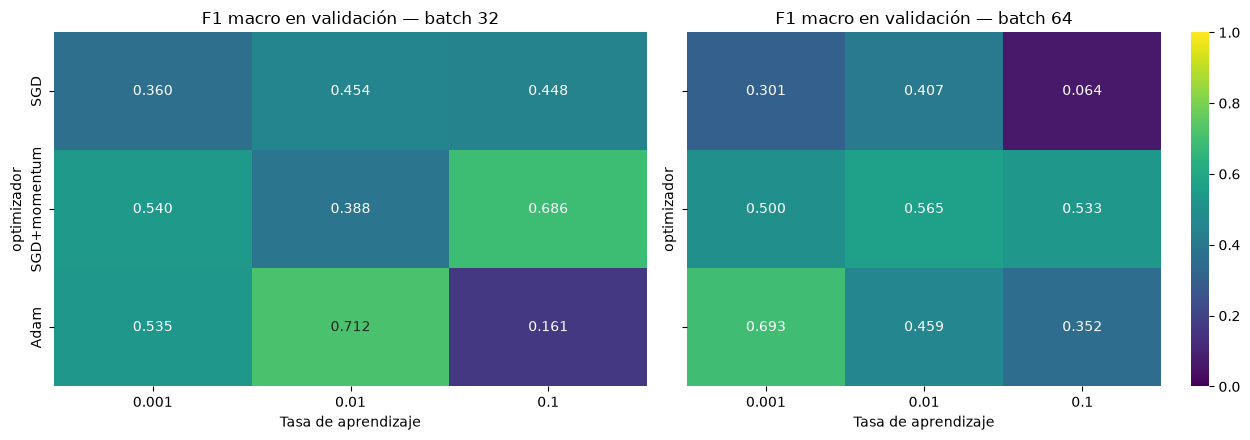

In [ ]:
grilla_a = [{'optimizador': o, 'lr': lr, 'batch': b, 'dropout': 0.3, 'aumentacion': False}
            for o in ['SGD', 'SGD+momentum', 'Adam'] for lr in [0.001, 0.01, 0.1] for b in [32, 64]]
res_a, hist_a = ejecutar_experimentos('grilla_a', grilla_a, [SEED], Xbus, ybus, EPOCAS['grilla_a'], PACIENCIA['grilla_a'])

columnas = ['optimizador', 'lr', 'batch', 'val_macro_f1', 'val_accuracy', 'mejor_epoca', 'epocas_ejecutadas', 'segundos', 'divergio']
display(res_a.sort_values('val_macro_f1', ascending=False)[columnas].reset_index(drop=True).round(4))

# Mapas de calor: F1 macro de validación por optimizador y LR, uno por tamaño de batch
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for eje, b in zip(ejes, [32, 64]):
    tabla = res_a[res_a.batch == b].pivot(index='optimizador', columns='lr', values='val_macro_f1').loc[['SGD', 'SGD+momentum', 'Adam']]
    sns.heatmap(tabla, annot=True, fmt='.3f', cmap='viridis', vmin=0, vmax=1, ax=eje, cbar=b == 64)
    eje.set_title(f'F1 macro en validación — batch {b}')
    eje.set_xlabel('Tasa de aprendizaje')
plt.tight_layout()
plt.show()

,"F1 con LR=0,001 (de a uno)",mejor F1 en la grilla,LR del mejor,batch del mejor
optimizador,,,,
SGD,0.3603,0.4535,0.01,32
SGD+momentum,0.5403,0.6863,0.10,32
Adam,0.5349,0.7119,0.01,32


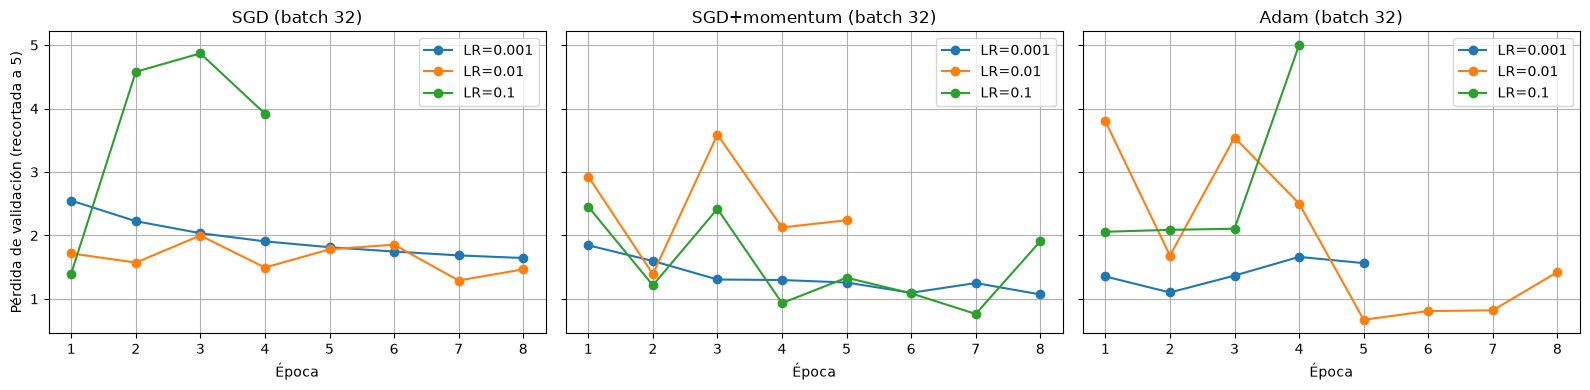

In [ ]:
# ¿Qué habría concluido la comparación de a un hiperparámetro (como en la EP1)?
# Se fija LR=0,001 y batch=32 (valores por defecto de Keras) y solo se cambia el optimizador.
de_a_uno = res_a[(res_a.lr == 0.001) & (res_a.batch == 32)].set_index('optimizador')['val_macro_f1']
mejor_por_optimizador = res_a.loc[res_a.groupby('optimizador')['val_macro_f1'].idxmax()].set_index('optimizador')
contraste = pd.DataFrame({
    'F1 con LR=0,001 (de a uno)': de_a_uno,
    'mejor F1 en la grilla': mejor_por_optimizador['val_macro_f1'],
    'LR del mejor': mejor_por_optimizador['lr'],
    'batch del mejor': mejor_por_optimizador['batch']}).loc[['SGD', 'SGD+momentum', 'Adam']]
display(contraste.round(4))

# Curvas de pérdida de validación: cómo se comporta cada optimizador con un LR bajo y uno alto (batch 32)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for eje, opt in zip(ejes, ['SGD', 'SGD+momentum', 'Adam']):
    for lr in [0.001, 0.01, 0.1]:
        clave = nombre_config({'optimizador': opt, 'lr': lr, 'batch': 32, 'dropout': 0.3, 'aumentacion': False}) + f' | semilla={SEED}'
        vl = np.array(hist_a[clave]['val_loss'], dtype=float)
        eje.plot(range(1, len(vl) + 1), np.clip(vl, 0, 5), marker='o', label=f'LR={lr}')
    eje.set_title(f'{opt} (batch 32)')
    eje.set_xlabel('Época')
    eje.grid(True)
    eje.legend()
ejes[0].set_ylabel('Pérdida de validación (recortada a 5)')
plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import Markdown, display
mejor_a = res_a.sort_values('val_macro_f1', ascending=False).iloc[0]
mejor_sgd = res_a[res_a.optimizador == 'SGD'].sort_values('val_macro_f1', ascending=False).iloc[0]
sgd_001 = res_a[(res_a.optimizador == 'SGD') & (res_a.lr == 0.001) & (res_a.batch == 32)].iloc[0]
frontera = res_a.sort_values('val_macro_f1', ascending=False).iloc[1]
display(Markdown(f"""**¿Qué pasó en la grilla A?** La mejor combinación con la semilla {SEED} fue **{mejor_a.optimizador}**, LR={mejor_a.lr:g}, batch={int(mejor_a.batch)}, con F1 macro de validación **{mejor_a.val_macro_f1:.4f}** (accuracy {mejor_a.val_accuracy:.4f}). La segunda alcanzó {frontera.val_macro_f1:.4f}: una ventaja de {mejor_a.val_macro_f1 - frontera.val_macro_f1:.4f}, que aún no demuestra superioridad estadística. Con SGD y LR=0,001/batch=32 el F1 fue {sgd_001.val_macro_f1:.4f}, mientras que su mejor combinación en la grilla, LR={mejor_sgd.lr:g}/batch={int(mejor_sgd.batch)}, obtuvo {mejor_sgd.val_macro_f1:.4f}. **Interpretación:** medir SGD solo con LR=0,001 puede dar una conclusión equivocada sobre el optimizador; el LR y el batch interactúan con él. Las celdas del mapa de calor y las curvas muestran el resultado medido, no valores simulados."""))
en_limite = res_a[res_a.mejor_epoca == res_a.epocas_ejecutadas]
display(Markdown(f"""**Límite de épocas (lo que observó el profe en la EP1).** En **{len(en_limite)} de {len(res_a)}** corridas la mejor época fue la última permitida ({EPOCAS['grilla_a']}): {', '.join(f'{f.optimizador} LR={f.lr:g}/batch={int(f.batch)}' for f in en_limite.itertuples())}. Esos modelos todavía estaban mejorando, así que su F1 está **subestimado**: la grilla compara configuraciones con el mismo presupuesto de épocas, no su rendimiento máximo. **Cómo lo abordamos:** la grilla B usa hasta {EPOCAS['grilla_b']} épocas, y el modelo final (9.1) se entrena con hasta {EPOCAS['final']} épocas y `EarlyStopping`, donde se verifica si la mejor época queda lejos del límite."""))

**¿Qué pasó en la grilla A?** La mejor combinación con la semilla 42 fue **Adam**, LR=0.01, batch=32, con F1 macro de validación **0.7119** (accuracy 0.7775). La segunda alcanzó 0.6930: una ventaja de 0.0189, que aún no demuestra superioridad estadística. Con SGD y LR=0,001/batch=32 el F1 fue 0.3603, mientras que su mejor combinación en la grilla, LR=0.01/batch=32, obtuvo 0.4535. **Interpretación:** medir SGD solo con LR=0,001 puede dar una conclusión equivocada sobre el optimizador; el LR y el batch interactúan con él. Las celdas del mapa de calor y las curvas muestran el resultado medido, no valores simulados.

**Límite de épocas (lo que observó el profe en la EP1).** En **5 de 18** corridas la mejor época fue la última permitida (8): SGD LR=0.001/batch=32, SGD LR=0.001/batch=64, SGD+momentum LR=0.001/batch=32, SGD+momentum LR=0.001/batch=64, Adam LR=0.1/batch=64. Esos modelos todavía estaban mejorando, así que su F1 está **subestimado**: la grilla compara configuraciones con el mismo presupuesto de épocas, no su rendimiento máximo. **Cómo lo abordamos:** la grilla B usa hasta 10 épocas, y el modelo final (9.1) se entrena con hasta 30 épocas y `EarlyStopping`, donde se verifica si la mejor época queda lejos del límite.

### 8.4 Grilla B: regularización (Dropout × aumentación) sobre los dos mejores de la grilla A

**Cómo.** Se toman las **dos mejores combinaciones** de optimizador, LR y batch de la grilla A y se cruzan con:

- **Dropout:** 0; 0,3 y 0,5.
- **Aumentación de datos:** sí o no.

Son 2 × 3 × 2 = **12 modelos**.

**Por qué cruzarlos y no "integrar ganadores".** En la EP1 elegimos el LR sin regularización y después le sumamos L2 + Dropout sin probar esa combinación. La regularización cambia la superficie de pérdida y la velocidad de convergencia, así que el mejor LR sin regularización no tiene por qué ser el mejor con ella. Al cruzar las dos mejores bases con todas las opciones de regularización, cada combinación se mide directamente.

Además del F1 macro, se registra la **brecha entre accuracy de entrenamiento y de validación** en la mejor época: una brecha grande indica sobreajuste. Con Dropout y aumentación, el accuracy de entrenamiento se mide con la regularización activa, por lo que la brecha puede ser incluso negativa.

Bases tomadas de la grilla A:


,optimizador,lr,batch
0,Adam,0.010,32
1,Adam,0.001,64


[1/12] Adam | lr=0.01 | batch=32 | dropout=0.0 | aug=no | semilla=42 -> F1 macro 0.6854 | mejor época 6/10 | 96 s


[2/12] Adam | lr=0.01 | batch=32 | dropout=0.0 | aug=sí | semilla=42 -> F1 macro 0.4868 | mejor época 3/7 | 75 s


[3/12] Adam | lr=0.01 | batch=32 | dropout=0.3 | aug=no | semilla=42 -> F1 macro 0.8126 | mejor época 9/10 | 82 s


[4/12] Adam | lr=0.01 | batch=32 | dropout=0.3 | aug=sí | semilla=42 -> F1 macro 0.5633 | mejor época 6/10 | 98 s


... (5 outputs left out)

[10/12] Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=sí | semilla=42 -> F1 macro 0.6536 | mejor época 10/10 | 139 s


[11/12] Adam | lr=0.001 | batch=64 | dropout=0.5 | aug=no | semilla=42 -> F1 macro 0.6582 | mejor época 9/10 | 157 s


[12/12] Adam | lr=0.001 | batch=64 | dropout=0.5 | aug=sí | semilla=42 -> F1 macro 0.6071 | mejor época 8/10 | 262 s
grilla_b: 12 corridas disponibles.


,base,dropout,aumentación,val_macro_f1,val_accuracy,brecha_train_val,mejor_epoca,epocas_ejecutadas,segundos
0,Adam | lr=0.01 | batch=32,0.3,no,0.8126,0.8246,-0.0221,9,10,82.2
1,Adam | lr=0.01 | batch=32,0.5,no,0.7381,0.7620,0.0046,10,10,84.2
2,Adam | lr=0.001 | batch=64,0.3,no,0.6930,0.7642,0.0004,7,10,131.8
3,Adam | lr=0.01 | batch=32,0.0,no,0.6854,0.7267,0.0797,6,10,95.6
4,Adam | lr=0.001 | batch=64,0.5,no,0.6582,0.7277,0.0012,9,10,157.2
5,Adam | lr=0.001 | batch=64,0.3,sí,0.6536,0.7248,0.0376,10,10,138.8
6,Adam | lr=0.001 | batch=64,0.5,sí,0.6071,0.6818,-0.0028,8,10,261.7
7,Adam | lr=0.01 | batch=32,0.3,sí,0.5633,0.6253,0.0883,6,10,97.7
8,Adam | lr=0.001 | batch=64,0.0,no,0.5531,0.6567,0.1675,5,9,104.7
9,Adam | lr=0.01 | batch=32,0.5,sí,0.5303,0.6169,-0.0833,2,6,64.9


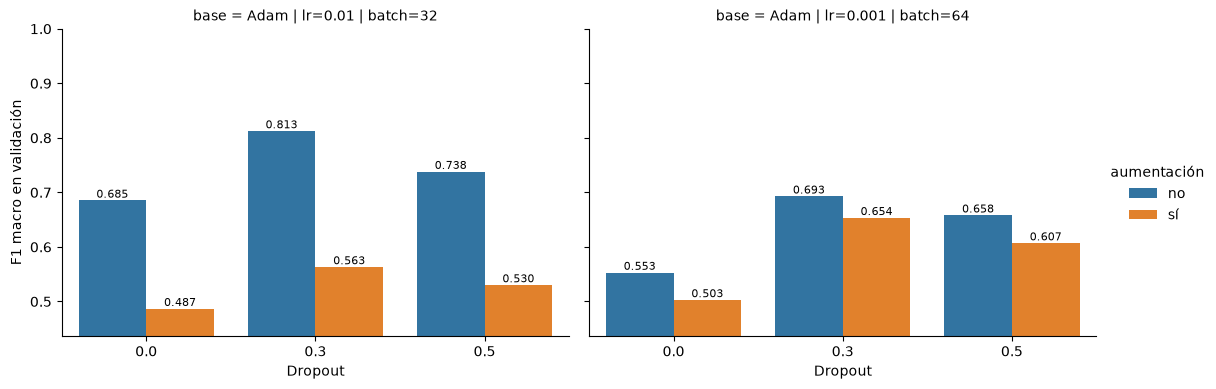

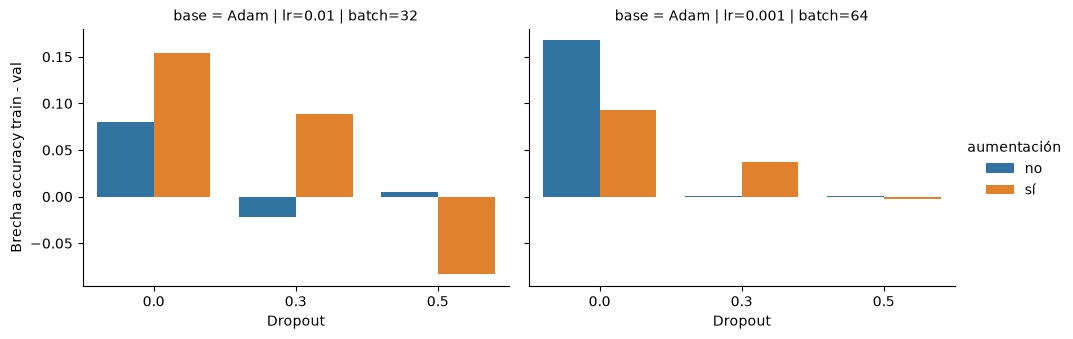

In [ ]:
claves_base = ['optimizador', 'lr', 'batch']
top2_a = res_a.sort_values('val_macro_f1', ascending=False).drop_duplicates(claves_base).head(2)[claves_base]
print('Bases tomadas de la grilla A:')
display(top2_a.reset_index(drop=True))

grilla_b = [{'optimizador': fila.optimizador, 'lr': float(fila.lr), 'batch': int(fila.batch), 'dropout': d, 'aumentacion': a}
            for fila in top2_a.itertuples() for d in [0.0, 0.3, 0.5] for a in [False, True]]
res_b, hist_b = ejecutar_experimentos('grilla_b', grilla_b, [SEED], Xbus, ybus, EPOCAS['grilla_b'], PACIENCIA['grilla_b'])
res_b['base'] = res_b.optimizador + ' | lr=' + res_b.lr.astype(str) + ' | batch=' + res_b.batch.astype(str)
res_b['aumentación'] = np.where(res_b.aumentacion, 'sí', 'no')

display(res_b.sort_values('val_macro_f1', ascending=False)[['base', 'dropout', 'aumentación', 'val_macro_f1', 'val_accuracy',
                                                             'brecha_train_val', 'mejor_epoca', 'epocas_ejecutadas', 'segundos']].reset_index(drop=True).round(4))

g = sns.catplot(data=res_b, x='dropout', y='val_macro_f1', hue='aumentación', col='base', kind='bar', height=4, aspect=1.4)
g.set_axis_labels('Dropout', 'F1 macro en validación')
lim_inf = max(0, res_b.val_macro_f1.min() - 0.05)
for eje in g.axes.flat:
    eje.set_ylim(lim_inf, 1)
    for barras in eje.containers:
        eje.bar_label(barras, fmt='%.3f', fontsize=8)
plt.show()

g = sns.catplot(data=res_b, x='dropout', y='brecha_train_val', hue='aumentación', col='base', kind='bar', height=3.5, aspect=1.4)
g.set_axis_labels('Dropout', 'Brecha accuracy train - val')
plt.show()

In [ ]:
mejor_b = res_b.sort_values('val_macro_f1', ascending=False).iloc[0]
sin_reg = res_b[(res_b.base == mejor_b.base) & (res_b.dropout == 0) & (~res_b.aumentacion)]
delta = mejor_b.val_macro_f1 - sin_reg.iloc[0].val_macro_f1 if len(sin_reg) else float('nan')
display(Markdown(f"""**¿Qué pasó con la regularización?** Al cruzar cada base con Dropout y aumentación, la mayor F1 macro con la semilla {SEED} fue **{mejor_b.val_macro_f1:.4f}** ({mejor_b.base}, Dropout={mejor_b.dropout:g}, aumentación={'sí' if mejor_b.aumentacion else 'no'}). Respecto a la misma base sin regularización, la diferencia fue **{delta:+.4f}** (positiva = mejora, negativa = empeora). Su brecha accuracy entrenamiento−validación en la mejor época fue {mejor_b.brecha_train_val:+.4f}. **Interpretación:** Dropout o aumentación no se presuponen superiores; se decide por el F1 observado. Una brecha grande y positiva sugiere sobreajuste; con aumentación o Dropout la brecha puede ser negativa porque la regularización solo se aplica al entrenamiento. Esta comparación usa una semilla; antes de elegir se repite con semillas nuevas."""))
misma = lambda r: r[(r.optimizador == mejor_b.optimizador) & (r.lr == mejor_b.lr) & (r.batch == mejor_b.batch) & (r.dropout == mejor_b.dropout) & (r.aumentacion == mejor_b.aumentacion)]
en_a = misma(res_a)
if len(en_a):
    f_a = en_a.iloc[0]
    display(Markdown(f"""**Efecto del presupuesto de entrenamiento.** La configuración ganadora ya estaba en la grilla A con la misma semilla y los mismos datos: allí obtuvo **{f_a.val_macro_f1:.4f}** (máximo {EPOCAS['grilla_a']} épocas, paciencia {PACIENCIA['grilla_a']}, mejor época {int(f_a.mejor_epoca)} de {int(f_a.epocas_ejecutadas)} ejecutadas) y aquí **{mejor_b.val_macro_f1:.4f}** (máximo {EPOCAS['grilla_b']} épocas, paciencia {PACIENCIA['grilla_b']}, mejor época {int(mejor_b.mejor_epoca)}). Solo cambian el máximo de épocas y la paciencia de `EarlyStopping`. En la grilla A la pérdida de validación no mejoró durante {PACIENCIA['grilla_a']} épocas seguidas y el entrenamiento se detuvo; con más margen, la red volvió a mejorar después. **Conclusión:** la pérdida de validación no baja en forma monótona, y un corte demasiado temprano subestima una configuración. Por eso el modelo final usa más épocas y más paciencia (9.1). Lo mismo puede afectar a las variantes con aumentación, que convergen más lento; con este presupuesto no podemos concluir que la aumentación sea perjudicial."""))

**¿Qué pasó con la regularización?** Al cruzar cada base con Dropout y aumentación, la mayor F1 macro con la semilla 42 fue **0.8126** (Adam | lr=0.01 | batch=32, Dropout=0.3, aumentación=no). Respecto a la misma base sin regularización, la diferencia fue **+0.1272** (positiva = mejora, negativa = empeora). Su brecha accuracy entrenamiento−validación en la mejor época fue -0.0221. **Interpretación:** Dropout o aumentación no se presuponen superiores; se decide por el F1 observado. Una brecha grande y positiva sugiere sobreajuste; con aumentación o Dropout la brecha puede ser negativa porque la regularización solo se aplica al entrenamiento. Esta comparación usa una semilla; antes de elegir se repite con semillas nuevas.

**Efecto del presupuesto de entrenamiento.** La configuración ganadora ya estaba en la grilla A con la misma semilla y los mismos datos: allí obtuvo **0.7119** (máximo 8 épocas, paciencia 3, mejor época 5 de 8 ejecutadas) y aquí **0.8126** (máximo 10 épocas, paciencia 4, mejor época 9). Solo cambian el máximo de épocas y la paciencia de `EarlyStopping`. En la grilla A la pérdida de validación no mejoró durante 3 épocas seguidas y el entrenamiento se detuvo; con más margen, la red volvió a mejorar después. **Conclusión:** la pérdida de validación no baja en forma monótona, y un corte demasiado temprano subestima una configuración. Por eso el modelo final usa más épocas y más paciencia (9.1). Lo mismo puede afectar a las variantes con aumentación, que convergen más lento; con este presupuesto no podemos concluir que la aumentación sea perjudicial.

### 8.5 Verificación con varias semillas: ¿la diferencia supera al ruido?

**Cómo.** Los **tres mejores candidatos** de la grilla B se vuelven a entrenar con tres semillas nuevas (1, 2 y 3). La semilla cambia la inicialización de los pesos, el orden de los lotes y el Dropout. Para cada candidato se informa la media y la desviación estándar del F1 macro de validación.

**Por qué.** En la EP1 todas las comparaciones usaron la semilla 42, y las diferencias que definieron a los ganadores (0,005–0,013 en F1) eran menores que la variación entre semillas. Además, el puntaje del ganador de una búsqueda tiende a ser optimista, porque se eligió justamente por haber salido alto con esa semilla. Por eso se usan semillas **distintas** de la de la búsqueda.

**Regla de decisión.** Gana el candidato con mayor F1 medio. Si otro candidato está a menos de una desviación estándar de él, se considera empatado, y entre los empatados se elige el más estable (menor desviación) y, después, el más rápido de entrenar.

[1/9] Adam | lr=0.01 | batch=32 | dropout=0.3 | aug=no | semilla=1 -> F1 macro 0.7653 | mejor época 10/10 | 185 s


[2/9] Adam | lr=0.01 | batch=32 | dropout=0.3 | aug=no | semilla=2 -> F1 macro 0.6457 | mejor época 10/10 | 121 s


[3/9] Adam | lr=0.01 | batch=32 | dropout=0.3 | aug=no | semilla=3 -> F1 macro 0.7143 | mejor época 7/10 | 97 s


[4/9] Adam | lr=0.01 | batch=32 | dropout=0.5 | aug=no | semilla=1 -> F1 macro 0.3703 | mejor época 4/8 | 76 s


[5/9] Adam | lr=0.01 | batch=32 | dropout=0.5 | aug=no | semilla=2 -> F1 macro 0.4190 | mejor época 3/7 | 69 s


[6/9] Adam | lr=0.01 | batch=32 | dropout=0.5 | aug=no | semilla=3 -> F1 macro 0.7123 | mejor época 7/10 | 108 s


[7/9] Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=no | semilla=1 -> F1 macro 0.6747 | mejor época 8/10 | 121 s


[8/9] Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=no | semilla=2 -> F1 macro 0.6597 | mejor época 6/10 | 110 s


[9/9] Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=no | semilla=3 -> F1 macro 0.7574 | mejor época 8/10 | 104 s
semillas: 9 corridas disponibles.


,f1_medio,f1_desv,acc_media,mejor_epoca_media,segundos_medios,f1_semilla_42,empatado_con_lider
config,,,,,,,
Adam | lr=0.01 | batch=32 | dropout=0.3 | aug=no,0.7084,0.0600,0.7527,9.0000,134.1000,0.8126,True
Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=no,0.6973,0.0526,0.7643,7.3333,111.7667,0.6930,True
Adam | lr=0.01 | batch=32 | dropout=0.5 | aug=no,0.5005,0.1850,0.5891,4.6667,84.4000,0.7381,False


Umbral de empate (media del líder - 1 desviación): 0.6484
Configuración elegida: Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=no


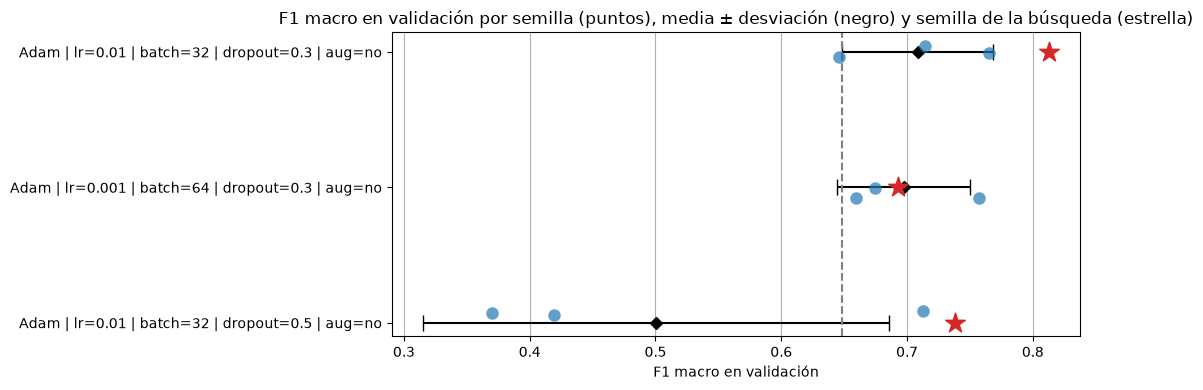

In [ ]:
top3_b = res_b.sort_values('val_macro_f1', ascending=False).head(3)
candidatos = [{'optimizador': f.optimizador, 'lr': float(f.lr), 'batch': int(f.batch), 'dropout': float(f.dropout),
               'aumentacion': bool(f.aumentacion)} for f in top3_b.itertuples()]
res_s, hist_s = ejecutar_experimentos('semillas', candidatos, SEMILLAS_VERIFICACION, Xbus, ybus, EPOCAS['semillas'], PACIENCIA['semillas'])

resumen = res_s.groupby('config').agg(f1_medio=('val_macro_f1', 'mean'), f1_desv=('val_macro_f1', 'std'),
                                      acc_media=('val_accuracy', 'mean'), mejor_epoca_media=('mejor_epoca', 'mean'),
                                      segundos_medios=('segundos', 'mean'))
resumen['f1_semilla_42'] = top3_b.set_index('config').loc[resumen.index, 'val_macro_f1']
resumen = resumen.sort_values('f1_medio', ascending=False)

lider = resumen.index[0]
umbral = resumen.loc[lider, 'f1_medio'] - resumen.loc[lider, 'f1_desv']
resumen['empatado_con_lider'] = resumen.f1_medio >= umbral
config_elegida_nombre = resumen[resumen.empatado_con_lider].sort_values(['f1_desv', 'segundos_medios']).index[0]
config_elegida = next(c for c in candidatos if nombre_config(c) == config_elegida_nombre)
display(resumen.round(4))
print(f"Umbral de empate (media del líder - 1 desviación): {umbral:.4f}")
print(f"Configuración elegida: {config_elegida_nombre}")

# Gráfico: cada punto es una semilla; la barra negra es media ± desviación; la estrella es el puntaje de la búsqueda (semilla 42)
fig, eje = plt.subplots(figsize=(11, 4))
orden = list(resumen.index)
sns.stripplot(data=res_s, y='config', x='val_macro_f1', order=orden, size=9, alpha=0.7, ax=eje, color='tab:blue')
for i, cfg in enumerate(orden):
    eje.errorbar(resumen.loc[cfg, 'f1_medio'], i, xerr=resumen.loc[cfg, 'f1_desv'], fmt='D', color='black', capsize=6)
    eje.scatter(resumen.loc[cfg, 'f1_semilla_42'], i, marker='*', s=220, color='tab:red', zorder=3)
eje.axvline(umbral, ls='--', color='gray')
eje.set_title('F1 macro en validación por semilla (puntos), media ± desviación (negro) y semilla de la búsqueda (estrella)')
eje.set_xlabel('F1 macro en validación')
eje.set_ylabel('')
eje.grid(True, axis='x')
plt.tight_layout()
plt.show()

In [ ]:
lider_m = resumen.iloc[0]
elegido_m = resumen.loc[config_elegida_nombre]
ventaja = lider_m.f1_medio - resumen.iloc[1].f1_medio
display(Markdown(f"""**¿Qué pasó al cambiar la semilla?** El candidato con mayor media de F1 macro alcanzó **{lider_m.f1_medio:.4f} ± {lider_m.f1_desv:.4f}** (tres semillas nuevas). La diferencia frente al segundo fue **{ventaja:.4f}**: {'menor' if ventaja < lider_m.f1_desv else 'mayor'} que una desviación estándar del líder. La configuración elegida es **{config_elegida_nombre}**, con F1 medio **{elegido_m.f1_medio:.4f} ± {elegido_m.f1_desv:.4f}**: se prioriza la estabilidad entre candidatos cuyo rendimiento está dentro del ruido medido. La estrella roja del gráfico representa la única semilla de la búsqueda (42); no se utiliza como prueba de que un candidato sea consistentemente mejor."""))

**¿Qué pasó al cambiar la semilla?** El candidato con mayor media de F1 macro alcanzó **0.7084 ± 0.0600** (tres semillas nuevas). La diferencia frente al segundo fue **0.0112**: menor que una desviación estándar del líder. La configuración elegida es **Adam | lr=0.001 | batch=64 | dropout=0.3 | aug=no**, con F1 medio **0.6973 ± 0.0526**: se prioriza la estabilidad entre candidatos cuyo rendimiento está dentro del ruido medido. La estrella roja del gráfico representa la única semilla de la búsqueda (42); no se utiliza como prueba de que un candidato sea consistentemente mejor.

### 8.6 Configuración final de hiperparámetros

La tabla resume los valores elegidos y la evidencia de cada uno. El número de épocas no se fija a mano: el modelo final se entrena con un máximo holgado y `EarlyStopping` decide cuándo parar (sección 9.1).

In [ ]:
tabla_final = pd.DataFrame([
    ['Arquitectura', 'CNN compacta: 3 bloques Conv-BN-ReLU-MaxPool (32-64-128) + GAP + Dense(15)',
     f'8.2: {model.count_params() / cnn_compacta.count_params():.0f} veces menos parámetros que la base a la misma resolución'],
    ['Resolución', f'{IMG_EXP}x{IMG_EXP}', '8.1: cómputo viable sin GPU'],
    ['Optimizador', config_elegida['optimizador'], '8.3: grilla optimizador × LR × batch'],
    ['Tasa de aprendizaje', config_elegida['lr'], '8.3: grilla optimizador × LR × batch'],
    ['Batch', config_elegida['batch'], '8.3: grilla optimizador × LR × batch'],
    ['Dropout', config_elegida['dropout'], '8.4: grilla de regularización'],
    ['Aumentación de datos', 'sí' if config_elegida['aumentacion'] else 'no', '8.4: grilla de regularización'],
    ['Épocas', f"máximo {EPOCAS['final']} con EarlyStopping (paciencia {PACIENCIA['final']})", '8.6 / 9.1: la mejor época no queda en el límite'],
    ['Selección', 'F1 macro medio en 3 semillas', '8.5: verificación con varias semillas'],
], columns=['Hiperparámetro', 'Valor elegido', 'Evidencia'])
display(tabla_final)

,Hiperparámetro,Valor elegido,Evidencia
0,Arquitectura,CNN compacta: 3 bloques Conv-BN-ReLU-MaxPool (...,8.2: 17 veces menos parámetros que la base a l...
1,Resolución,64x64,8.1: cómputo viable sin GPU
2,Optimizador,Adam,8.3: grilla optimizador × LR × batch
3,Tasa de aprendizaje,0.001,8.3: grilla optimizador × LR × batch
4,Batch,64,8.3: grilla optimizador × LR × batch
5,Dropout,0.3,8.4: grilla de regularización
6,Aumentación de datos,no,8.4: grilla de regularización
7,Épocas,máximo 30 con EarlyStopping (paciencia 6),8.6 / 9.1: la mejor época no queda en el límite
8,Selección,F1 macro medio en 3 semillas,8.5: verificación con varias semillas


## 9. Justificación del modelo final

### 9.1 Entrenamiento del modelo final con todos los datos de entrenamiento

**Cómo.** La configuración elegida en 8.5 se entrena con el **100 % del entrenamiento** a 64×64, usando las mismas tres semillas de la verificación, con un máximo holgado de épocas y `EarlyStopping` sobre la pérdida de validación.

**Por qué.** La búsqueda usó solo una parte de los datos para que fuera viable. Con todos los datos el modelo ve más ejemplos de cada clase, sobre todo de las más pequeñas. Entrenar con tres semillas permite informar el rendimiento final como media ± desviación y no como un único número que podría ser afortunado. Para el análisis detallado (9.3) se usa la semilla con mejor F1 de **validación**: la prueba nunca interviene en ninguna elección.

Semilla 1: F1 macro val 0.8287 | mejor época 13 de 19 (máximo 30) | 758 s


Semilla 2: F1 macro val 0.9186 | mejor época 18 de 24 (máximo 30) | 898 s


Semilla 3: F1 macro val 0.8488 | mejor época 11 de 17 (máximo 30) | 567 s

Modelo para el análisis detallado: semilla 2 (mejor F1 macro en validación)


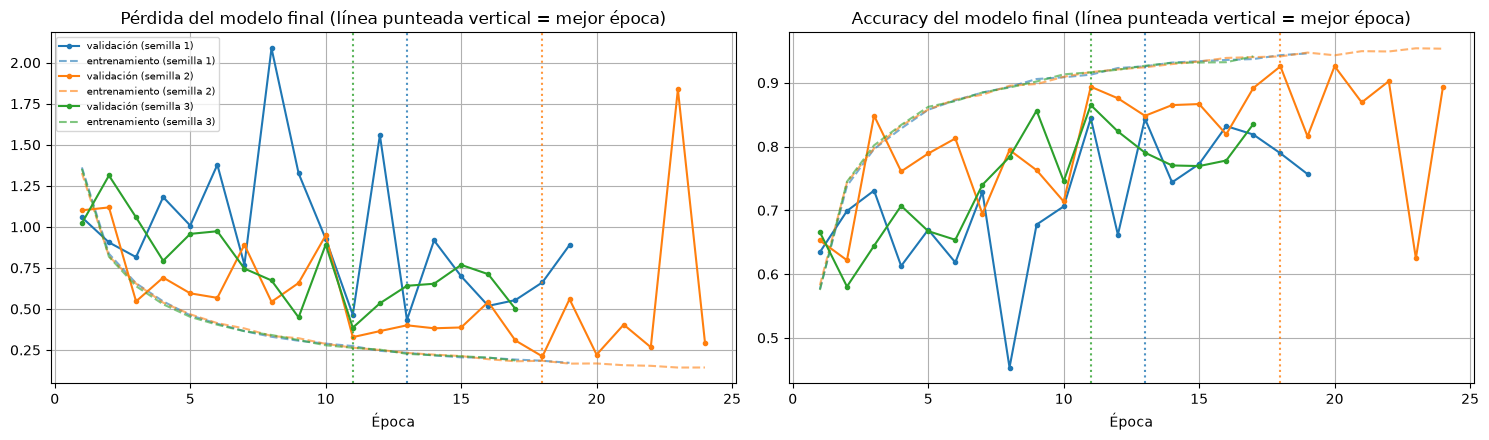

In [ ]:
modelos_finales, metricas_finales, historias_finales = {}, {}, {}
for s in SEMILLAS_VERIFICACION:
    ruta_modelo = os.path.join(RESULTADOS_DIR, f'modelo_final_semilla{s}.keras')
    ruta_info = os.path.join(RESULTADOS_DIR, f'modelo_final_semilla{s}.json')
    if os.path.exists(ruta_modelo) and os.path.exists(ruta_info) and not REENTRENAR:
        modelos_finales[s] = keras.models.load_model(ruta_modelo)
        info = json.load(open(ruta_info))
        metricas_finales[s], historias_finales[s] = info['metricas'], info['historia']
    else:
        modelos_finales[s], metricas_finales[s], historias_finales[s] = entrenar_configuracion(
            config_elegida, s, Xtr_s, y_train, Xva_s, y_val, EPOCAS['final'], PACIENCIA['final'])
        modelos_finales[s].save(ruta_modelo)
        json.dump({'metricas': metricas_finales[s], 'historia': {k: [float(v) for v in vals] for k, vals in historias_finales[s].items()}},
                  open(ruta_info, 'w'))
    m = metricas_finales[s]
    print(f"Semilla {s}: F1 macro val {m['val_macro_f1']:.4f} | mejor época {m['mejor_epoca']} de {m['epocas_ejecutadas']} "
          f"(máximo {EPOCAS['final']}) | {m['segundos']:.0f} s")

semilla_final = max(metricas_finales, key=lambda s: metricas_finales[s]['val_macro_f1'])
modelo_final = modelos_finales[semilla_final]
print(f"\nModelo para el análisis detallado: semilla {semilla_final} (mejor F1 macro en validación)")

# Curvas de aprendizaje de las tres semillas con la mejor época marcada
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
for s, h in historias_finales.items():
    ep = range(1, len(h['loss']) + 1)
    mejor = metricas_finales[s]['mejor_epoca']
    for eje, metrica in zip(ejes, ['loss', 'accuracy']):
        linea, = eje.plot(ep, h[f'val_{metrica}'], marker='o', ms=3, label=f'validación (semilla {s})')
        eje.plot(ep, h[metrica], ls='--', color=linea.get_color(), alpha=0.6, label=f'entrenamiento (semilla {s})')
        eje.axvline(mejor, color=linea.get_color(), ls=':', alpha=0.8)
for eje, titulo in zip(ejes, ['Pérdida', 'Accuracy']):
    eje.set_title(f'{titulo} del modelo final (línea punteada vertical = mejor época)')
    eje.set_xlabel('Época')
    eje.grid(True)
ejes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [ ]:
med_ep = [metricas_finales[s]['mejor_epoca'] for s in SEMILLAS_VERIFICACION]
med_f1 = [metricas_finales[s]['val_macro_f1'] for s in SEMILLAS_VERIFICACION]
toco_limite = [s for s in SEMILLAS_VERIFICACION if metricas_finales[s]['mejor_epoca'] == EPOCAS['final']]
display(Markdown(f"""**¿Qué pasó al usar todo el entrenamiento?** Con tres inicializaciones, el F1 macro de validación fue **{np.mean(med_f1):.4f} ± {np.std(med_f1, ddof=1):.4f}**, y las mejores épocas fueron {med_ep} (máximo {EPOCAS['final']}). {'Advertencia: la mejor época coincidió con el máximo al menos una vez; se recomienda ampliar el presupuesto de épocas antes de concluir convergencia.' if toco_limite else 'La mejor época no fue la última en ninguna corrida: el máximo no truncó el resultado observado.'} Las curvas permiten ver si la pérdida de entrenamiento sigue cayendo mientras la de validación sube (sobreajuste) o si ambas siguen mejorando (entrenamiento insuficiente). La semilla {semilla_final} se eligió por su F1 de validación, no por el de prueba."""))

**¿Qué pasó al usar todo el entrenamiento?** Con tres inicializaciones, el F1 macro de validación fue **0.8654 ± 0.0472**, y las mejores épocas fueron [13, 18, 11] (máximo 30). La mejor época no fue la última en ninguna corrida: el máximo no truncó el resultado observado. Las curvas permiten ver si la pérdida de entrenamiento sigue cayendo mientras la de validación sube (sobreajuste) o si ambas siguen mejorando (entrenamiento insuficiente). La semilla 2 se eligió por su F1 de validación, no por el de prueba.

### 9.2 Comparación con alternativas

**Cómo.** El modelo final se compara con tres alternativas de naturaleza distinta, todas entrenadas con el mismo conjunto de entrenamiento:

1. **CNN base (secciones 3–7):** la primera arquitectura, con la resolución y las épocas de la sección 4 (150×150 y 5 épocas con GPU; **64×64 y 2 épocas en esta ejecución sin GPU**). Con tan pocas épocas la base queda en desventaja: la diferencia frente a ella exagera la mejora real de la optimización.
2. **Random Forest sin ajustar** [13] (100 árboles) sobre los píxeles de la imagen reducida a 32×32. Es la **línea base no neuronal** que pidió la retroalimentación: si una CNN no le gana claramente a un modelo simple, no se justifica su costo.
3. **Transfer learning con MobileNetV2** preentrenada en ImageNet, congelada, a 96×96 (la resolución mínima con pesos publicados). Solo se entrena una cabeza `Dropout(0,3)` + `Dense(15)` sobre sus características, con tres semillas. Representa la alternativa "red grande preentrenada" que la sección 3 mencionó sin probar [10]. **Limitación de esta ejecución:** sin GPU las imágenes se cargaron a 64×64, así que MobileNetV2 recibe imágenes **ampliadas** de 64 a 96 píxeles, con menos detalle del que tendría a 96×96 reales. Su resultado es, por lo tanto, una estimación conservadora; si igual empata con la CNN compacta, con más resolución o ajuste fino (*fine-tuning*) podría superarla.

La **elección se hace con el F1 macro de validación**, igual que en toda la sección 8. Las columnas de prueba se muestran para informar el rendimiento esperado, no para elegir. También se mide el **tiempo de inferencia por imagen**, que importa si el modelo se usa en un equipo sin GPU.

,F1 macro val,F1 macro test,accuracy test,parámetros,entrenamiento (s),inferencia (ms/imagen)
modelo,,,,,,
CNN base 64x64 (sección 3),0.7276,0.7050,0.7826,1627087,NaN,0.2409
Random Forest (píxeles 32x32),0.6082,0.6231,0.7158,582680,6.0,0.0172
MobileNetV2 congelada 96x96 (transfer learning),0.9122,0.9028,0.9125,2277199,44.7,1.5458
CNN compacta optimizada 64x64 (modelo final),0.9186,0.9029,0.9176,95855,897.5,0.5752


,F1 macro val (media ± desv.),F1 macro test (media ± desv.)
CNN compacta optimizada (3 semillas),0.8654 ± 0.0472,0.8572 ± 0.0434
MobileNetV2 congelada (3 semillas de la cabeza),0.9107 ± 0.0025,—


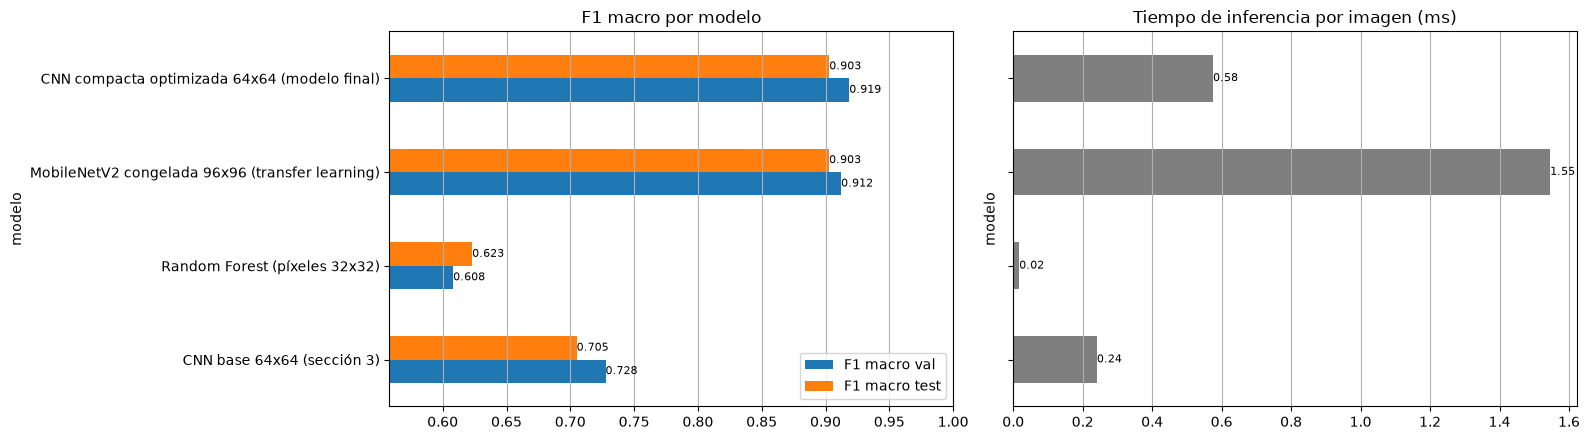

In [ ]:
from sklearn.ensemble import RandomForestClassifier


def evaluar(nombre, pred_val, pred_test, parametros, seg_entrenamiento, ms_por_imagen):
    return {'modelo': nombre,
            'F1 macro val': f1_score(y_val, pred_val, average='macro'),
            'F1 macro test': f1_score(y_test, pred_test, average='macro'),
            'accuracy test': accuracy_score(y_test, pred_test),
            'parámetros': parametros, 'entrenamiento (s)': seg_entrenamiento, 'inferencia (ms/imagen)': ms_por_imagen}


def predecir(modelo, X):
    t0 = time.time()
    pred = np.argmax(modelo.predict(X, batch_size=256, verbose=0), axis=1)
    return pred, (time.time() - t0) / len(X) * 1000


filas_comparacion = []

# 1. CNN base de la sección 3, ya entrenada en la sección 4
pred_val_base, _ = predecir(model, X_val)
pred_test_base, ms_base = predecir(model, X_test)
filas_comparacion.append(evaluar(f'CNN base {IMG_SIZE[0]}x{IMG_SIZE[1]} (sección 3)', pred_val_base, pred_test_base, model.count_params(), np.nan, ms_base))

# 2. Random Forest sin ajustar sobre píxeles 32x32
X32 = {k: redimensionar(X, 32).reshape(len(X), -1) for k, X in [('train', X_train), ('val', X_val), ('test', X_test)]}
t0 = time.time()
bosque = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED).fit(X32['train'], y_train)
seg_rf = time.time() - t0
t0 = time.time()
pred_test_rf = bosque.predict(X32['test'])
ms_rf = (time.time() - t0) / len(y_test) * 1000
filas_comparacion.append(evaluar('Random Forest (píxeles 32x32)', bosque.predict(X32['val']), pred_test_rf,
                                 sum(e.tree_.node_count for e in bosque.estimators_), round(seg_rf, 1), ms_rf))

# 3. MobileNetV2 congelada + cabeza densa (características precalculadas una vez)
base_mnv2 = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet', pooling='avg')
base_mnv2.trainable = False
preprocesar = keras.applications.mobilenet_v2.preprocess_input
t0 = time.time()
caract = {k: base_mnv2.predict(preprocesar(redimensionar(X, 96).astype('float32')), batch_size=256, verbose=0)
          for k, X in [('train', X_train), ('val', X_val), ('test', X_test)]}
seg_caract = time.time() - t0
resultados_mnv2 = []
for s in SEMILLAS_VERIFICACION:
    keras.backend.clear_session()
    keras.utils.set_random_seed(s)
    cabeza = keras.Sequential([layers.Input((caract['train'].shape[1],)), layers.Dropout(0.3), layers.Dense(num_classes, activation='softmax')])
    cabeza.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    cabeza.fit(caract['train'], y_train, validation_data=(caract['val'], y_val), epochs=40, batch_size=64, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)])
    resultados_mnv2.append((f1_score(y_val, np.argmax(cabeza.predict(caract['val'], verbose=0), axis=1), average='macro'),
                            s, cabeza, time.time() - t0))
f1_mnv2_val = [r[0] for r in resultados_mnv2]
_, semilla_mnv2, cabeza_mnv2, seg_cabeza = max(resultados_mnv2, key=lambda r: r[0])
modelo_mnv2 = keras.Sequential([layers.Input((96, 96, 3)), layers.Lambda(lambda x: preprocesar(tf.cast(x, tf.float32))), base_mnv2, cabeza_mnv2])
X96_val, X96_test = redimensionar(X_val, 96), redimensionar(X_test, 96)
pred_test_mnv2, ms_mnv2 = predecir(modelo_mnv2, X96_test)
filas_comparacion.append(evaluar('MobileNetV2 congelada 96x96 (transfer learning)', predecir(modelo_mnv2, X96_val)[0], pred_test_mnv2,
                                 modelo_mnv2.count_params(), round(seg_caract + seg_cabeza, 1), ms_mnv2))

# 4. Modelo final (CNN compacta optimizada)
pred_val_final, _ = predecir(modelo_final, Xva_s)
pred_test_final, ms_final = predecir(modelo_final, Xte_s)
filas_comparacion.append(evaluar(f'CNN compacta optimizada {IMG_EXP}x{IMG_EXP} (modelo final)', pred_val_final, pred_test_final,
                                 modelo_final.count_params(), metricas_finales[semilla_final]['segundos'], ms_final))

comparacion = pd.DataFrame(filas_comparacion).set_index('modelo')
display(comparacion.round(4))

# Variabilidad entre semillas de los dos modelos que se entrenaron con varias semillas
f1_final_val = [metricas_finales[s]['val_macro_f1'] for s in SEMILLAS_VERIFICACION]
f1_final_test = [f1_score(y_test, predecir(modelos_finales[s], Xte_s)[0], average='macro') for s in SEMILLAS_VERIFICACION]
variabilidad = pd.DataFrame({
    'F1 macro val (media ± desv.)': [f'{np.mean(f1_final_val):.4f} ± {np.std(f1_final_val, ddof=1):.4f}',
                                     f'{np.mean(f1_mnv2_val):.4f} ± {np.std(f1_mnv2_val, ddof=1):.4f}'],
    'F1 macro test (media ± desv.)': [f'{np.mean(f1_final_test):.4f} ± {np.std(f1_final_test, ddof=1):.4f}', '—']},
    index=['CNN compacta optimizada (3 semillas)', 'MobileNetV2 congelada (3 semillas de la cabeza)'])
display(variabilidad)

# Gráfico comparativo
fig, ejes = plt.subplots(1, 2, figsize=(16, 4.5))
comparacion[['F1 macro val', 'F1 macro test']].plot.barh(ax=ejes[0])
ejes[0].set_xlim(max(0, comparacion[['F1 macro val', 'F1 macro test']].min().min() - 0.05), 1)
ejes[0].set_title('F1 macro por modelo')
ejes[0].grid(True, axis='x')
for barras in ejes[0].containers:
    ejes[0].bar_label(barras, fmt='%.3f', fontsize=8)
comparacion['inferencia (ms/imagen)'].plot.barh(ax=ejes[1], color='tab:gray')
ejes[1].set_title('Tiempo de inferencia por imagen (ms)')
ejes[1].grid(True, axis='x')
for barras in ejes[1].containers:
    ejes[1].bar_label(barras, fmt='%.2f', fontsize=8)
ejes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

In [ ]:
orden_val = comparacion['F1 macro val'].sort_values(ascending=False)
mejor_nombre = orden_val.index[0]
base_f1 = comparacion.iloc[0]['F1 macro val']
compacta_f1 = comparacion.iloc[-1]['F1 macro val']
mnv2_f1 = comparacion.iloc[-2]['F1 macro val']
ventaja_compacta = compacta_f1 - mnv2_f1
# Comparación predefinida en validación: MobileNetV2 debe superar a la CNN compacta
# por un margen mayor que la variación observada entre semillas para justificar su costo.
margen = max(0.01, np.std(f1_final_val, ddof=1))
print(f'Margen de decisión MobileNetV2 vs CNN compacta: {margen:.4f} F1 macro en validación')
if mnv2_f1 > compacta_f1 + margen:
    nombre_seleccionado = 'MobileNetV2 congelada'
    modelo_seleccionado, X_test_seleccionado = modelo_mnv2, X96_test
    pred_test_seleccionado = pred_test_mnv2
    pred_val_seleccionado = predecir(modelo_mnv2, X96_val)[0]
    semilla_seleccionada = semilla_mnv2
else:
    nombre_seleccionado = 'CNN compacta optimizada'
    modelo_seleccionado, X_test_seleccionado = modelo_final, Xte_s
    pred_test_seleccionado, pred_val_seleccionado = pred_test_final, pred_val_final
    semilla_seleccionada = semilla_final
# Para las siguientes secciones, los nombres modelo_final y pred_test_final se refieren
# a la alternativa elegida exclusivamente sobre validación, antes de leer el test.
modelo_final = modelo_seleccionado
pred_test_final = pred_test_seleccionado
pred_val_final = pred_val_seleccionado
semilla_final = semilla_seleccionada
Xte_s = X_test_seleccionado
brecha_mejor = max(orden_val.iloc[0] - orden_val.iloc[1], 0)
display(Markdown(f"""**¿Qué pasó al comparar arquitecturas?** La CNN base obtuvo F1 macro de validación **{base_f1:.4f}**; la compacta optimizada, **{compacta_f1:.4f}**; MobileNetV2 congelada, **{mnv2_f1:.4f}**; y Random Forest, **{comparacion.iloc[1]['F1 macro val']:.4f}**. La mejor cifra absoluta de validación es **{mejor_nombre}** ({orden_val.iloc[0]:.4f}), pero una diferencia de {brecha_mejor:.4f} frente al segundo no demuestra por sí sola una ventaja estable. **Decisión predefinida:** elegimos **{nombre_seleccionado}**: MobileNetV2 solo sustituye a la CNN compacta si supera su F1 de validación por más de max(0,01, desviación entre semillas) = **{margen:.4f}**, para no pagar el mayor costo por una diferencia dentro del ruido. Se decidió con validación; el conjunto de prueba no intervino. La tabla muestra también rendimiento en prueba e inferencia, para comprobar la generalización y el costo real, pero esos números no cambiaron la elección."""))

Margen de decisión MobileNetV2 vs CNN compacta: 0.0472 F1 macro en validación


**¿Qué pasó al comparar arquitecturas?** La CNN base obtuvo F1 macro de validación **0.7276**; la compacta optimizada, **0.9186**; MobileNetV2 congelada, **0.9122**; y Random Forest, **0.6082**. La mejor cifra absoluta de validación es **CNN compacta optimizada 64x64 (modelo final)** (0.9186), pero una diferencia de 0.0064 frente al segundo no demuestra por sí sola una ventaja estable. **Decisión predefinida:** elegimos **CNN compacta optimizada**: MobileNetV2 solo sustituye a la CNN compacta si supera su F1 de validación por más de max(0,01, desviación entre semillas) = **0.0472**, para no pagar el mayor costo por una diferencia dentro del ruido. Se decidió con validación; el conjunto de prueba no intervino. La tabla muestra también rendimiento en prueba e inferencia, para comprobar la generalización y el costo real, pero esos números no cambiaron la elección.

### 9.3 Evaluación del modelo final en el conjunto de prueba

**Cómo.** El modelo final se evalúa **una sola vez** sobre las imágenes de prueba, que no se usaron en ninguna decisión. Se reportan accuracy, precision, recall y F1 por clase, la matriz de confusión normalizada (cada fila suma 1, así que se lee como "de las hojas de esta clase, qué proporción se predijo como cada clase") y los pares de clases que más se confunden.

=== Modelo final en PRUEBA (semilla 2) ===

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9720    0.9329    0.9521       149
                     Pepper__bell___healthy     0.9520    0.9820    0.9667       222
                      Potato___Early_blight     0.9456    0.9267    0.9360       150
                       Potato___Late_blight     0.8881    0.8467    0.8669       150
                           Potato___healthy     0.6667    0.9565    0.7857        23
                      Tomato_Bacterial_spot     0.9673    0.9279    0.9472       319
                        Tomato_Early_blight     0.9444    0.6800    0.7907       150
                         Tomato_Late_blight     0.8893    0.7587    0.8189       286
                           Tomato_Leaf_Mold     0.7684    0.9510    0.8500       143
                  Tomato_Septoria_leaf_spot     0.9200    0.9511    0.9353       266
Tomato_Spider_mites_

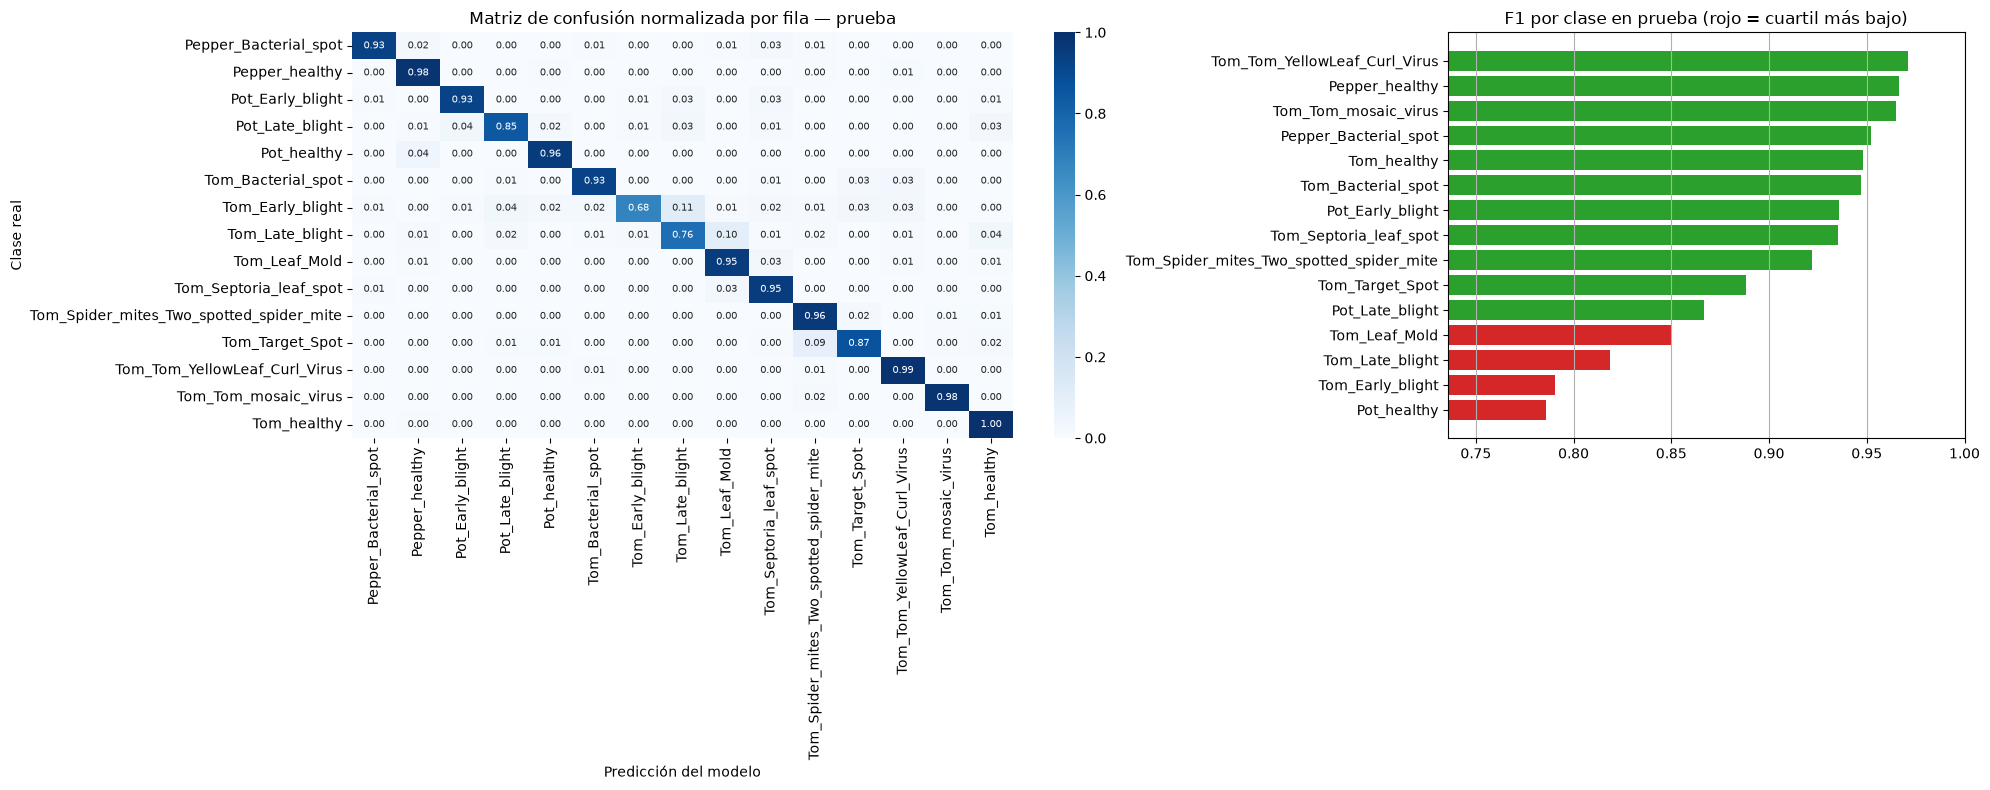

,clase real,predicha como,casos,proporción de la clase real
0,Tomato_Late_blight,Tomato_Leaf_Mold,29,0.101
1,Tomato__Target_Spot,Tomato_Spider_mites_Two_spotted_spider_mite,18,0.085
2,Tomato_Early_blight,Tomato_Late_blight,17,0.113
3,Tomato_Late_blight,Tomato_healthy,12,0.042
4,Tomato_Bacterial_spot,Tomato__Tomato_YellowLeaf__Curl_Virus,10,0.031
5,Tomato_Septoria_leaf_spot,Tomato_Leaf_Mold,9,0.034
6,Tomato_Bacterial_spot,Tomato__Target_Spot,8,0.025
7,Potato___Late_blight,Potato___Early_blight,6,0.040


Errores totales en prueba: 255 de 3096


In [ ]:
print(f"=== Modelo final en PRUEBA (semilla {semilla_final}) ===\n")
print(classification_report(y_test, pred_test_final, target_names=class_names, digits=4))

reporte_test = pd.DataFrame(classification_report(y_test, pred_test_final, target_names=class_names, output_dict=True)).T.iloc[:num_classes]
nombres_cortos = [c.replace('Tomato', 'Tom').replace('Pepper__bell', 'Pepper').replace('Potato', 'Pot').replace('__', '_').replace('__', '_')
                  for c in class_names]

fig, ejes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [1.6, 1]})
cm_test = confusion_matrix(y_test, pred_test_final)
cm_norm = cm_test / cm_test.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=nombres_cortos, yticklabels=nombres_cortos, ax=ejes[0],
            annot_kws={'size': 7}, vmin=0, vmax=1)
ejes[0].set_title('Matriz de confusión normalizada por fila — prueba')
ejes[0].set_xlabel('Predicción del modelo')
ejes[0].set_ylabel('Clase real')
orden_f1 = reporte_test['f1-score'].sort_values()
colores = ['tab:red' if v < orden_f1.quantile(0.25) else 'tab:green' for v in orden_f1]
ejes[1].barh([nombres_cortos[class_names.index(c)] for c in orden_f1.index], orden_f1.values, color=colores)
ejes[1].set_xlim(max(0, orden_f1.min() - 0.05), 1)
ejes[1].set_title('F1 por clase en prueba (rojo = cuartil más bajo)')
ejes[1].grid(True, axis='x')
plt.tight_layout()
plt.show()

# Pares de clases más confundidos
errores = [(class_names[i], class_names[j], cm_test[i, j], cm_test[i, j] / cm_test[i].sum())
           for i in range(num_classes) for j in range(num_classes) if i != j and cm_test[i, j] > 0]
top_confusiones = pd.DataFrame(errores, columns=['clase real', 'predicha como', 'casos', 'proporción de la clase real']) \
    .sort_values('casos', ascending=False).head(8).reset_index(drop=True)
display(top_confusiones.round(3))
print(f"Errores totales en prueba: {int((pred_test_final != y_test).sum())} de {len(y_test)}")

#### Errores con consecuencia práctica: hoja enferma clasificada como sana

No todos los errores cuestan lo mismo. Confundir dos enfermedades del tomate es un error de diagnóstico, pero **clasificar una hoja enferma como sana** (un falso negativo de enfermedad) hace que no se trate un cultivo infectado, y la enfermedad puede extenderse. El caso inverso (una hoja sana clasificada como enferma, un falso positivo) cuesta una revisión o un tratamiento innecesario. Por eso se cuentan ambos tipos de error por separado.

,casos,sobre
Enferma predicha como sana (falso negativo de enfermedad),44,2612
Sana predicha como enferma (falso positivo de enfermedad),3,484
Enfermedad confundida con otra enfermedad,205,2612


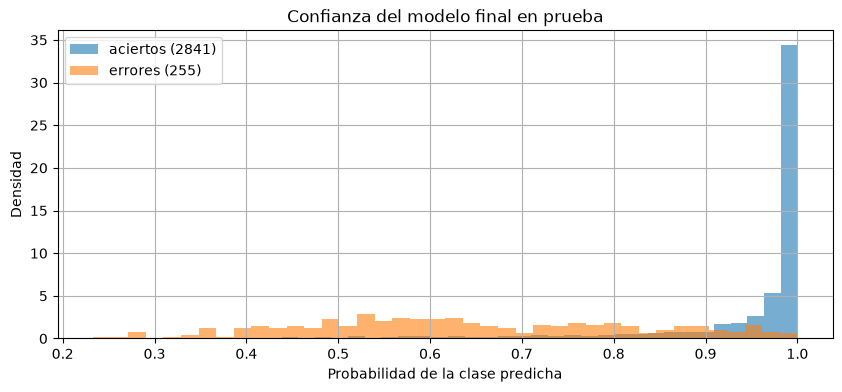

,umbral de confianza,% de imágenes derivadas a revisión manual,% de los errores que quedan en revisión,accuracy en las aceptadas
0,0.5,2.907,22.745,0.934
1,0.7,10.820,61.961,0.965
2,0.9,22.351,90.196,0.990


In [ ]:
clases_sanas = [i for i, c in enumerate(class_names) if 'healthy' in c]
real_sana, pred_sana = np.isin(y_test, clases_sanas), np.isin(pred_test_final, clases_sanas)
enferma_como_sana = int((~real_sana & pred_sana).sum())
sana_como_enferma = int((real_sana & ~pred_sana).sum())
enferma_otra_enfermedad = int((~real_sana & ~pred_sana & (pred_test_final != y_test)).sum())
display(pd.DataFrame({
    'casos': [enferma_como_sana, sana_como_enferma, enferma_otra_enfermedad],
    'sobre': [int((~real_sana).sum()), int(real_sana.sum()), int((~real_sana).sum())]},
    index=['Enferma predicha como sana (falso negativo de enfermedad)',
           'Sana predicha como enferma (falso positivo de enfermedad)',
           'Enfermedad confundida con otra enfermedad']))

# ¿El modelo "sabe" cuándo duda? Confianza (probabilidad máxima) en aciertos y errores
prob_test = modelo_final.predict(Xte_s, batch_size=256, verbose=0)
confianza = prob_test.max(axis=1)
acierto = pred_test_final == y_test
fig, eje = plt.subplots(figsize=(10, 4))
eje.hist(confianza[acierto], bins=40, alpha=0.6, density=True, label=f'aciertos ({acierto.sum()})')
eje.hist(confianza[~acierto], bins=40, alpha=0.6, density=True, label=f'errores ({(~acierto).sum()})')
eje.set_xlabel('Probabilidad de la clase predicha')
eje.set_ylabel('Densidad')
eje.set_title('Confianza del modelo final en prueba')
eje.legend()
eje.grid(True)
plt.show()

umbrales = [0.5, 0.7, 0.9]
display(pd.DataFrame([{
    'umbral de confianza': u,
    '% de imágenes derivadas a revisión manual': 100 * (confianza < u).mean(),
    '% de los errores que quedan en revisión': 100 * (confianza[~acierto] < u).mean() if (~acierto).any() else np.nan,
    'accuracy en las aceptadas': accuracy_score(y_test[confianza >= u], pred_test_final[confianza >= u]) if (confianza >= u).any() else np.nan,
} for u in umbrales]).round(3))

#### Brecha entre validación y prueba

In [ ]:
brecha = pd.DataFrame({
    'validación': [f1_score(y_val, pred_val_final, average='macro'), accuracy_score(y_val, pred_val_final)],
    'prueba': [f1_score(y_test, pred_test_final, average='macro'), accuracy_score(y_test, pred_test_final)]},
    index=['F1 macro', 'accuracy'])
brecha['diferencia'] = brecha['prueba'] - brecha['validación']
display(brecha.round(4))

,validación,prueba,diferencia
F1 macro,0.9186,0.9029,-0.0157
accuracy,0.9257,0.9176,-0.0081


In [ ]:
f1_val_elegido = f1_score(y_val, pred_val_final, average='macro')
f1_test_elegido = f1_score(y_test, pred_test_final, average='macro')
delta = f1_test_elegido - f1_val_elegido
peor_clase = reporte_test['f1-score'].idxmin()
mayor_confusion = top_confusiones.iloc[0] if len(top_confusiones) else None
conf_texto = (f"El error más frecuente fue **{mayor_confusion['clase real']} → {mayor_confusion['predicha como']}** ({int(mayor_confusion.casos)} casos)." if mayor_confusion is not None else 'No hubo confusiones entre clases.')
display(Markdown(f"""**¿Qué pasó en prueba?** El modelo **{nombre_seleccionado}** obtuvo F1 macro **{f1_test_elegido:.4f}** y accuracy **{accuracy_score(y_test, pred_test_final):.4f}**. La clase más débil fue **{peor_clase}**, con F1 **{reporte_test.loc[peor_clase, 'f1-score']:.4f}** ({int(reporte_test.loc[peor_clase, 'support'])} muestras de prueba). {conf_texto} Se clasificaron **{enferma_como_sana}** hojas enfermas como sanas y **{sana_como_enferma}** hojas sanas como enfermas; el primer error es especialmente peligroso porque retrasa una intervención. Frente al F1 macro de validación ({f1_val_elegido:.4f}), la prueba cambió **{delta:+.4f}**. {'La caída es compatible con un sesgo optimista de validación: tras probar muchas configuraciones sobre el mismo conjunto, el máximo seleccionado puede ser afortunado. También intervienen la variación de la muestra y las clases poco frecuentes; no podemos atribuir toda la brecha a una sola causa.' if delta < 0 else 'Que la prueba haya salido mejor no demuestra que el modelo generalice mejor: los conjuntos son muestras distintas y los resultados varían con las clases menos representadas.'} El F1 macro evidencia los fallos en clases pequeñas que el accuracy global podría ocultar."""))

**¿Qué pasó en prueba?** El modelo **CNN compacta optimizada** obtuvo F1 macro **0.9029** y accuracy **0.9176**. La clase más débil fue **Potato___healthy**, con F1 **0.7857** (23 muestras de prueba). El error más frecuente fue **Tomato_Late_blight → Tomato_Leaf_Mold** (29 casos). Se clasificaron **44** hojas enfermas como sanas y **3** hojas sanas como enfermas; el primer error es especialmente peligroso porque retrasa una intervención. Frente al F1 macro de validación (0.9186), la prueba cambió **-0.0157**. La caída es compatible con un sesgo optimista de validación: tras probar muchas configuraciones sobre el mismo conjunto, el máximo seleccionado puede ser afortunado. También intervienen la variación de la muestra y las clases poco frecuentes; no podemos atribuir toda la brecha a una sola causa. El F1 macro evidencia los fallos en clases pequeñas que el accuracy global podría ocultar.

In [ ]:
from IPython.display import Markdown, display
riesgo = (f'{enferma_como_sana} de {(~real_sana).sum()} hojas enfermas clasificadas como sanas '
          f'({enferma_como_sana / (~real_sana).sum():.1%})')
clases_dificiles = ', '.join(reporte_test.sort_values('f1-score').head(3).index)
display(Markdown(f"""### 9.4 Cuándo no usar el modelo

**No usarlo como diagnóstico autónomo ni para decidir descartar un tratamiento sin inspección humana.** En prueba hubo **{riesgo}**: son falsos negativos de enfermedad que podrían dejar un cultivo infectado sin atención. También hubo **{sana_como_enferma}** hojas sanas clasificadas como enfermas (riesgo de tratamiento innecesario). Las clases con menor F1 fueron **{clases_dificiles}**; allí la predicción es menos fiable. Si la confianza es baja, una opción es derivar a revisión manual, pero los umbrales de la tabla anterior solo describen lo observado en prueba: **no deben elegirse mirando la prueba**, deben validarse en datos nuevos antes de ponerse en producción.

PlantVillage tiene imágenes capturadas bajo condiciones controladas. En fotos de campo (fondos, iluminación, variedad de hoja o enfermedades nuevas) el rendimiento puede cambiar; no se evaluó ese cambio de dominio. El uso defendible hoy es **apoyo al diagnóstico con revisión humana**, nunca único criterio sanitario. Este límite está ligado a nuestros errores observados, no a una advertencia genérica."""))

### 9.4 Cuándo no usar el modelo

**No usarlo como diagnóstico autónomo ni para decidir descartar un tratamiento sin inspección humana.** En prueba hubo **44 de 2612 hojas enfermas clasificadas como sanas (1.7%)**: son falsos negativos de enfermedad que podrían dejar un cultivo infectado sin atención. También hubo **3** hojas sanas clasificadas como enfermas (riesgo de tratamiento innecesario). Las clases con menor F1 fueron **Potato___healthy, Tomato_Early_blight, Tomato_Late_blight**; allí la predicción es menos fiable. Si la confianza es baja, una opción es derivar a revisión manual, pero los umbrales de la tabla anterior solo describen lo observado en prueba: **no deben elegirse mirando la prueba**, deben validarse en datos nuevos antes de ponerse en producción.

PlantVillage tiene imágenes capturadas bajo condiciones controladas. En fotos de campo (fondos, iluminación, variedad de hoja o enfermedades nuevas) el rendimiento puede cambiar; no se evaluó ese cambio de dominio. El uso defendible hoy es **apoyo al diagnóstico con revisión humana**, nunca único criterio sanitario. Este límite está ligado a nuestros errores observados, no a una advertencia genérica.

In [ ]:
from IPython.display import Markdown, display
display(Markdown(f"""### 9.5 Decisión final y conclusiones

En conclusión, logramos optimizar nuestra CNN, alcanzando una precisión del **91,76% y un F1 macro del 90,29%**. Elegimos la CNN compacta porque obtuvo un rendimiento similar al de modelos más complejos, pero utilizando muchos menos parámetros.

Esto demuestra que una arquitectura más grande no siempre es mejor y que una buena optimización permite obtener resultados eficientes."""))

### 9.5 Decisión final y conclusiones

En conclusión, logramos optimizar nuestra CNN, alcanzando una precisión del **91,76% y un F1 macro del 90,29%**. Elegimos la CNN compacta porque obtuvo un rendimiento similar al de modelos más complejos, pero utilizando muchos menos parámetros.

Esto demuestra que una arquitectura más grande no siempre es mejor y que una buena optimización permite obtener resultados eficientes.